# Entrega 3 · Modelado Supervisado

**Grupo:** 10 · Comisión 5K09 (5K09-10)

**Integrantes:**
- Bustelo Nicolás
- Cuello Joaquin
- Lemos Augusto
- Masuet Juan Pablo
- Vazquez Manuel

**Dataset:** OpenAlex — Artículos de Ciencia de Materiales publicados en 2019 (`openalex_silver_enriched.csv`)

---

## Hoja de ruta

Este notebook se ejecuta **de arriba hacia abajo** con una única semilla (`SEMILLA = 42`) y continúa el trabajo de la Entrega 2 siguiendo la estructura de las Prácticas 1 y 2 de la Unidad 3:

| Sección | Qué pasa | Qué deja |
|---|---|---|
| **0. Qué cambió desde la Entrega 2** | Reconstrucción en un bloque del embudo de población y las columnas elegidas | `df` auditado (**10.326 artículos**) y trazabilidad completa |
| **1. El planteo: las 4 decisiones** | Objetivos, chequeo de fuga, métricas, partición (`KFold` vs `GroupKFold` por revista) y el `Pipeline` completo | `X_train`, `X_test`, transformador `PreparadorOpenAlex` y función `armar()` |
| **2. Objetivo 1: Regresión (`log(1 + cited_by_count)`)** | Piso (`DummyRegressor`), comparación de 4 familias por CV, curvas de complejidad, `GridSearchCV`, ablación de las 5 columnas en observación + chequeo de `oa_status`, y lectura del modelo final en el test | Modelo de regresión elegido, error por tramo de citas e importancia por permutación + coeficientes |
| **3. Objetivo 2: Clasificación (`is_top10_percent`)** | Piso (`DummyClassifier`), comparación de 4 familias por CV (`f1_macro`), `GridSearchCV`, tratamiento del desbalance (`class_weight` vs umbral en CV con curvas PR y ROC) y lectura en el test | Clasificador elegido con su umbral óptimo, matrices de confusión normalizadas, análisis de errores e interpretabilidad |
| **4. Objetivo 3: Clasificador por percentiles (terciles de citas)** | Análisis de la distribución y el balance (ancho fijo vs tramos vs terciles), comparación de 5 familias por CV con métricas ordinales (f1_macro, ±1 tercil, kappa cuadrático), ajuste de cortes y lectura en el test | Regresor del Objetivo 1 discretizado en terciles, matriz de confusión y puente con `is_top10_percent` |
| **5. Síntesis y preguntas de defensa** | Resumen de decisiones y respuestas directas a las 6 preguntas del instructivo | Guía de referencia rápida para la defensa oral y puente hacia la Entrega 4 |

## 0. Qué cambió desde la Entrega 2 y reconstrucción de la población

**Qué cambió desde la Entrega 2:**
1. Se mantienen sin cambios la definición de la población (**artículos de Ciencia de Materiales publicados en revistas en 2019, con al menos un autor, sin la edición alemana de *Angewandte Chemie* y sin títulos duplicados**) y las **12 columnas que entran + 5 en observación** surgidas de las cuatro hipótesis y de la tabla de candidatas de la Entrega 2, unificando las cifras del texto con la salida exacta del archivo `openalex_silver_enriched.csv` (**11.813 registros iniciales → 10.326 artículos** en la población filtrada).
2. Toda transformación que depende de los datos —como recortar las 15 editoriales y los 15 países más frecuentes de las columnas en observación, imputar medianas y estandarizar— se movió **adentro del método `fit` de un `Pipeline` de `scikit-learn`**, para que se calcule únicamente sobre los datos de entrenamiento de cada partición y nunca mire el conjunto de prueba.

In [1]:
# ============================================================
# 0.1 Semilla global, carga del dataset y embudo de la Entrega 2
# ============================================================
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier,
    HistGradientBoostingRegressor,
    HistGradientBoostingClassifier,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    GroupKFold,
    StratifiedGroupKFold,
    cross_val_score,
    cross_validate,
    cross_val_predict,
    validation_curve,
    GridSearchCV,
    TunedThresholdClassifierCV,
)
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score,
)
from sklearn.inspection import permutation_importance

# Semilla única definida una sola vez y pasada a todo objeto que use azar
SEMILLA = 42

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# Detección de entorno: Google Colab o Local
try:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
    except Exception as e:
        print(f"No se pudo montar Drive ({e}); se busca el dataset en /content")
    CARPETA = Path("/content/drive/MyDrive/Facultad/5to AÑO/Ciencia de Datos")
except ImportError:
    CARPETA = Path(".")

candidatos_archivo = [
    Path("openalex_silver_enriched.csv"),
    Path("ultimo_ok.csv.gz"),
    Path("ultimo_ok.csv"),
    CARPETA / "openalex_silver_enriched.csv",
    CARPETA / "ultimo_ok.csv.gz",
    CARPETA / "ultimo_ok.csv",
]
# Respaldo: copia comprimida subida a Files de Colab (/content/openalex_AAAA-MM-DD.csv.gz) o en el directorio actual
for carpeta_respaldo in [Path("/content"), Path(".")]:
    if carpeta_respaldo.exists():
        candidatos_archivo += sorted(carpeta_respaldo.glob("openalex*.csv*"), reverse=True)

ARCHIVO = next((p for p in candidatos_archivo if p.exists()), None)
if ARCHIVO is None:
    raise FileNotFoundError(f"No se encontró el dataset en el directorio actual, en /content ni en {CARPETA}")
print(f"Dataset: {ARCHIVO}")

df_crudo = pd.read_csv(ARCHIVO, low_memory=False)

# Indicadores previos y filtros de población definidos en la Entrega 2 (Sección 2 y 3)
df_crudo["in_pubmed"]         = df_crudo["ids_pmid"].notna()
df_crudo["sin_referencias"]   = df_crudo["referenced_works_count"] == 0
df_crudo["sin_instituciones"] = df_crudo["institutions_count"] == 0
df_crudo["fecha_imputada"]    = df_crudo["publication_date"] == "2019-01-01"

edicion_alemana = df_crudo["doi"].str.contains("/ange.", regex=False, na=False)
mascara = (
    (df_crudo["source_type"] == "journal")
    & (df_crudo["authors_count"] > 0)
    & (df_crudo["is_top10_percent"].notna())
    & (~edicion_alemana)
)
mas_citado_primero = df_crudo[mascara].sort_values("cited_by_count", ascending=False, kind="stable")
titulo_repetido = mas_citado_primero["title"].duplicated().reindex(df_crudo.index, fill_value=False)
mascara &= ~titulo_repetido

df = df_crudo[mascara].copy()

# Conversiones de tipos y recodificación de 'lv' -> 'en' (Entrega 2, Sección 4)
BOOLEANAS = ["is_top10_percent", "is_oa", "apc_paid", "source_is_core", "is_in_doaj", "in_pubmed"]
for c in BOOLEANAS:
    df[c] = df[c].map({True: True, False: False, "True": True, "False": False}).astype(bool)
df["language"] = df["language"].replace("lv", "en")
df["log_citas"] = np.log1p(df["cited_by_count"])

pd.Series({
    "Registros en capa Plata": len(df_crudo),
    "Población filtrada (artículos en revistas)": len(df),
    "Revistas distintas (primary_location_source_id)": df["primary_location_source_id"].nunique(),
    "Semilla global": SEMILLA,
})

Dataset: ultimo_ok.csv.gz


Registros en capa Plata                            11813
Población filtrada (artículos en revistas)         10326
Revistas distintas (primary_location_source_id)     2213
Semilla global                                        42
dtype: int64

## 1. El planteo: las cuatro decisiones antes del primer modelo

Antes de entrenar el primer modelo dejamos escritas las cuatro decisiones contra las que se lee todo el resto del trabajo: **qué predecimos (y qué columnas no pueden entrar)**, **con qué métrica medimos cada objetivo**, **cómo armamos la validación** y **cómo empaquetamos toda la preparación adentro de un `Pipeline`**.

### 1.1 Las variables objetivo y el chequeo de fuga

En la Entrega 2 analizamos dos variables objetivo que miden el impacto científico acumulado entre 2019 y octubre de 2026 desde dos ángulos complementarios:

1. **Objetivo numérico (Regresión): `log_citas = log(1 + cited_by_count)`**. Las citas crudas tienen una cola derecha extrema (mediana `13`, media `30,10`, máximo `1.722`, asimetría `10,57`), con un `11,0 %` de artículos sin citas y el `1 %` más citado concentrando el `16,4 %` de todas las citas. En escala logarítmica la distribución se vuelve prácticamente simétrica (media `2,502`, mediana `2,639`, desvío `1,418`, asimetría `-0,09`).
2. **Objetivo binario (Clasificación): `is_top10_percent`**. Vale `True` (`1`) si el artículo se ubicó en el `10 %` más citado de su campo y año según el percentil normalizado de OpenAlex (`12,0 %` de nuestra población filtrada de revistas; `1.234` artículos positivos contra `9.092` negativos).

**Las columnas que salen por fuga.** Al igual que en la sección 1.2 y 4.2 de la Práctica 1, antes de armar `X` verificamos qué columnas del dataset traen la respuesta escrita o se calculan después de publicar:
- **Fuga directa (se calculan con las citas del propio artículo):** `cited_by_count`, `is_top10_percent`, `fwci`, `citation_normalized_percentile_value`, `citation_normalized_percentile_is_in_top_1_percent`, `citation_normalized_percentile_is_in_top_10_percent`, `cited_by_percentile_year_min`, `cited_by_percentile_year_max`, `counts_by_year` y `counts_by_year_count`.
- **Fuga temporal (crecen con el tiempo después de publicar):** `locations_count`, `indexed_in_count` y `mesh_count`.

Se mide en dos líneas: `citation_normalized_percentile_value >= 0.90` reproduce `is_top10_percent` en el **100,0 %** de las filas, y `fwci` tiene una correlación de Spearman de **0,963** con `cited_by_count`. Dejar cualquiera de esas columnas daría un modelo con puntaje casi perfecto que no aprendió nada útil para predecir al momento de publicar.

In [2]:
# ============================================================
# 1.1 Verificación empírica de las columnas descartadas por fuga
# ============================================================
chequeo_fuga = pd.Series({
    "Coincidencia (citation_normalized_percentile_value >= 0.90) == is_top10_percent": (
        (df["citation_normalized_percentile_value"] >= 0.90) == df["is_top10_percent"]
    ).mean(),
    "Spearman(fwci, cited_by_count)": df["fwci"].corr(df["cited_by_count"], method="spearman"),
    "Spearman(counts_by_year_count, cited_by_count)": df["counts_by_year_count"].corr(df["cited_by_count"], method="spearman"),
}).round(4)

display(chequeo_fuga.to_frame("evidencia de fuga"))

,evidencia de fuga
Coincidencia (citation_normalized_percentile_value >= 0.90) == is_top10_percent,1.0000
"Spearman(fwci, cited_by_count)",0.9633
"Spearman(counts_by_year_count, cited_by_count)",0.9285


### 1.2 Las métricas declaradas antes de elegir

Ninguna métrica es correcta en abstracto; depende de la forma del objetivo y de qué error cuesta más:

| Problema | Objetivo | Métrica principal | Métrica de acompañamiento | Por qué se declara esta métrica |
|---|---|---|---|---|
| **Regresión** | `log(1 + cited_by_count)` | **MAE** (*Mean Absolute Error*) sobre `log(1 + citas)` | **$R^2$** (proporción de varianza explicada) y MAE en citas reales | El **MAE** se lee en las unidades del objetivo y promedia todos los artículos por igual, sin dejarse arrastrar por el `1 %` de artículos con más de `279` citas como ocurriría con el RMSE. Un MAE de $\Delta$ en escala `log(1 + citas)` equivale a errar por un factor multiplicativo de $e^{\Delta}$. Acompañamos con **$R^2$** porque continúa directamente el $\eta^2$ de la Entrega 2 (donde las categóricas de revista solas explicaban el `38,1 %` de la varianza). |
| **Clasificación** | `is_top10_percent` (`12,0 %` positivos) | **`f1_macro`** | **F1, Recall y Precision de la clase `top 10 %`** + **PR-AUC** | Con `88,0 %` de clase negativa (`False`) y `12,0 %` de clase positiva (`True`), la *accuracy* esconde por completo a la clase chica: un modelo que contesta siempre `False` acierta el `88,0 %` sin detectar un solo artículo destacado. El **`f1_macro`** promedia en partes iguales el F1 de ambas clases (`50 %` y `50 %`), penalizando tanto no encontrar a los artículos `top 10 %` (*recall* bajo) como dar falsas alarmas (*precision* baja). |

---

### 1.3 La partición y la validación cruzada («la validación imita el uso»)

Separamos los **10.326 artículos** en **entrenamiento (`80 %`, 8.260 artículos)** y **prueba (`20 %`, 2.066 artículos)** con `train_test_split(..., test_size=0.2, stratify=y_clf, random_state=SEMILLA)`. Estratificar por `is_top10_percent` garantiza dos cosas a la vez:
1. Mantiene exactamente el `12,0 %` de artículos `top 10 %` en entrenamiento y en prueba.
2. Conserva la misma media y mediana de `log(1 + cited_by_count)` en ambas partes, lo que nos permite usar **la misma partición de filas** para los dos objetivos sin que ningún modelo vea jamás los `2.066` artículos de `X_test` hasta la evaluación final.

**¿Por qué armamos los 5 folds por artículo (`KFold` / `StratifiedKFold`) y qué pasa si agrupamos por revista (`GroupKFold`)?**
- En nuestro dataset cada fila es un artículo distinto (`id` único) y todos fueron publicados en el mismo año (`2019`, donde la hipótesis H4 probó que el mes de publicación no influye: $\rho = -0,035$), por lo que no corresponde `TimeSeriesSplit`.
- Sin embargo, los `10.326` artículos provienen de `2.213` revistas (`primary_location_source_id`), y las variables más fuertes (`source_pre_cites_per_work`, `source_is_core`, `oa_status`, `in_pubmed`) describen a la revista.
- Si el modelo se usa para predecir el impacto de artículos nuevos publicados en el catálogo de revistas ya conocido de Ciencia de Materiales, los folds se arman por artículo al azar (`KFold` / `StratifiedKFold`). Si en cambio se quisiera usar sobre **revistas que el modelo nunca vio**, habría que agrupar por revista (`GroupKFold` / `StratifiedGroupKFold` con `groups=primary_location_source_id`). En la Sección 2.2 medimos ambos esquemas y demostramos qué ocurre con el número en cada caso.

In [3]:
# ============================================================
# 1.3 Selección de columnas candidatas (Entrega 2) y partición 80/20
# ============================================================
# Las 12 columnas que entran según la conclusión de la Entrega 2:
# - 8 numéricas continuas o de conteo (se transforman con log(1 + x))
# - sin_referencias (se deriva adentro del pipeline a partir de referenced_works_count == 0)
# - 2 booleanas de la revista (source_is_core, in_pubmed)
# - 1 categórica de acceso abierto (oa_status)
NUMERICAS_BASE = [
    "source_pre_cites_per_work",
    "referenced_works_count",
    "funders_count",
    "last_author_pre_cites",
    "first_author_pre_cites",
    "institution_max_h_index",
    "institutions_count",
    "authors_count",
]
BOOLEANAS_BASE = ["source_is_core", "in_pubmed"]
CATEGORICAS_BASE = ["oa_status"]

# Las 5 columnas que quedaron "en observación" en la Entrega 2 para probar en la Entrega 3
EN_OBSERVACION = [
    "primary_location_source_host_organization_name",
    "first_author_country",
    "language",
    "source_pre_works",
    "source_apc_usd",
]

COLUMNAS_X = NUMERICAS_BASE + BOOLEANAS_BASE + CATEGORICAS_BASE + EN_OBSERVACION

X = df[COLUMNAS_X].copy()
y_reg = df["log_citas"].copy()
y_clf = df["is_top10_percent"].astype(int).copy()
grupos_revista = df["primary_location_source_id"].copy()

# Partición única 80/20 estratificada por el objetivo binario
X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, stratify=y_clf, random_state=SEMILLA
)
grupos_train = grupos_revista.loc[X_train.index]

# Esquemas de validación cruzada de 5 folds sobre el entrenamiento
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

resumen_particion = pd.DataFrame({
    "Entrenamiento (X_train)": [
        len(X_train),
        y_reg_train.mean(),
        y_reg_train.std(),
        y_clf_train.mean() * 100,
    ],
    "Prueba (X_test)": [
        len(X_test),
        y_reg_test.mean(),
        y_reg_test.std(),
        y_clf_test.mean() * 100,
    ],
}, index=["Artículos", "Media log(1 + citas)", "Desvío log(1 + citas)", "% is_top10_percent"]).round(3)

display(resumen_particion)

,Entrenamiento (X_train),Prueba (X_test)
Artículos,8260.000,2066.000
Media log(1 + citas),2.500,2.512
Desvío log(1 + citas),1.416,1.427
% is_top10_percent,11.949,11.955


### 1.4 Todo adentro de un `Pipeline`: transformador propio y `ColumnTransformer`

En la Entrega 2 definimos transformaciones específicas para cada columna:
1. **Escala logarítmica (`log(1 + x)`)** para las 8 variables numéricas (`source_pre_cites_per_work`, `referenced_works_count`, `funders_count`, `last_author_pre_cites`, `first_author_pre_cites`, `institution_max_h_index`, `institutions_count`, `authors_count`), porque todas presentan asimetría positiva marcada.
2. **Indicadores de nulos estructurales y metadatos incompletos:** en la Entrega 2 probamos que los nulos de `source_pre_cites_per_work` (`1,0 %`, revistas sin historial en 2012–2018), `last_author_pre_cites` (`9,1 %`), `first_author_pre_cites` (`4,4 %`) e `institution_max_h_index` (`7,1 %`, que coincide exactamente con `institutions_count == 0`), así como los ceros de `referenced_works_count` (`10,4 %`, `sin_referencias`), no son datos perdidos al azar sino características estructurales o de registro. Antes de imputar la mediana, creamos los indicadores binarios (`sin_dato_revista`, `sin_dato_ultimo_autor`, `sin_dato_primer_autor`, `sin_instituciones`, `sin_referencias`).
3. **Hiperparámetros del transformador para medir las decisiones de la Entrega 2:** siguiendo el molde de la sección 2.7 de la Práctica 1, nuestra clase `PreparadorOpenAlex` hereda de `BaseEstimator` y `TransformerMixin`, implementa `fit`, `transform` y `get_feature_names_out`, y expone hiperparámetros para probar decisiones de columnas y chequeos de fuga por validación cruzada (con selección dinámica de columnas numéricas y categóricas adentro de `ColumnTransformer`):
   - `incluir_obs`: activa las 5 columnas en observación (aprendiendo en `fit` cuáles son las 15 editoriales y los 15 países más frecuentes de ese fold de entrenamiento y agrupando el resto en `"otras"` / `"otros"`).
   - `sin_fuga_oa`: en `oa_status`, recodifica `green` y `bronze` como `closed` para verificar la advertencia de la Hipótesis 2 de la Entrega 2 (ya que el depósito en un repositorio o la liberación *bronze* pueden ocurrir después de publicar).
   - `interaccion_oa_core`: agrega el cruce explícito `oa_status × source_is_core` que en la Hipótesis 2 de la Entrega 2 subía el $\eta^2$ de `0,275` a `0,335`.
   - `excluir`: permite quitar cualquier subconjunto de columnas de salida para auditar su impacto por ablación en validación cruzada.

In [4]:
# ============================================================
# 1.4 Transformador propio (PreparadorOpenAlex) y receta de Pipeline
# ============================================================
class PreparadorOpenAlex(BaseEstimator, TransformerMixin):
    '''Aplica las transformaciones definidas en la Entrega 2 adentro del pipeline.

    - incluir_obs=True: incorpora las 5 columnas en observación (aprendiendo el top_n en fit).
    - sin_fuga_oa=True: recodifica green y bronze como closed en oa_status (chequeo de H2).
    - interaccion_oa_core=True: agrega la interacción categórica oa_status × source_is_core.
    - excluir=(...): quita columnas de salida (para los chequeos de fuga por ablación).
    '''

    def __init__(self, incluir_obs=False, sin_fuga_oa=False, interaccion_oa_core=False, top_n=15, excluir=()):
        self.incluir_obs = incluir_obs
        self.sin_fuga_oa = sin_fuga_oa
        self.interaccion_oa_core = interaccion_oa_core
        self.top_n = top_n
        self.excluir = excluir

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        if self.incluir_obs:
            ed = X["primary_location_source_host_organization_name"].fillna("sin dato")
            self.top_editoriales_ = ed.value_counts().index[: self.top_n].tolist()
            pa = X["first_author_country"].fillna("sin dato")
            self.top_paises_ = pa.value_counts().index[: self.top_n].tolist()
        return self

    def transform(self, X):
        out = pd.DataFrame(index=X.index)

        # 1. Numéricas base en escala log(1 + x)
        for c in NUMERICAS_BASE:
            out[f"log_{c}"] = np.log1p(X[c].clip(lower=0))

        # 2. Indicadores de nulos estructurales y metadatos incompletos + booleanas base
        out["sin_dato_revista"]      = X["source_pre_cites_per_work"].isna().astype(int)
        out["sin_dato_ultimo_autor"] = X["last_author_pre_cites"].isna().astype(int)
        out["sin_dato_primer_autor"] = X["first_author_pre_cites"].isna().astype(int)
        out["sin_instituciones"]     = (X["institutions_count"] == 0).astype(int)
        out["sin_referencias"]       = (X["referenced_works_count"] == 0).astype(int)
        out["source_is_core"]        = X["source_is_core"].astype(int)
        out["in_pubmed"]             = X["in_pubmed"].astype(int)

        # 3. Categórica oa_status (con opción de chequeo sin green ni bronze)
        oa = X["oa_status"].astype(str)
        if self.sin_fuga_oa:
            oa = oa.replace({"green": "closed", "bronze": "closed"})
        out["oa_status"] = oa

        # 4. Interacción opcional oa_status × source_is_core (H2)
        if self.interaccion_oa_core:
            out["oa_x_core"] = oa + "_" + X["source_is_core"].astype(str)

        # 5. Las 5 columnas en observación (si incluir_obs=True)
        if self.incluir_obs:
            out["log_source_pre_works"] = np.log1p(X["source_pre_works"].clip(lower=0))
            out["log_source_apc_usd"]   = np.log1p(X["source_apc_usd"].clip(lower=0))
            out["sin_dato_apc"]         = X["source_apc_usd"].isna().astype(int)
            out["idioma_en"]            = (X["language"] == "en").astype(int)
            ed = X["primary_location_source_host_organization_name"].fillna("sin dato")
            out["editorial"]            = ed.where(ed.isin(self.top_editoriales_), "otras")
            pa = X["first_author_country"].fillna("sin dato")
            out["pais_primer_autor"]    = pa.where(pa.isin(self.top_paises_), "otros")

        if self.excluir:
            out = out.drop(columns=[c for c in self.excluir if c in out.columns])
        return out

    def get_feature_names_out(self, input_features=None):
        nombres = (
            [f"log_{c}" for c in NUMERICAS_BASE]
            + [
                "sin_dato_revista",
                "sin_dato_ultimo_autor",
                "sin_dato_primer_autor",
                "sin_instituciones",
                "sin_referencias",
                "source_is_core",
                "in_pubmed",
                "oa_status",
            ]
        )
        if self.interaccion_oa_core:
            nombres.append("oa_x_core")
        if self.incluir_obs:
            nombres.extend([
                "log_source_pre_works",
                "log_source_apc_usd",
                "sin_dato_apc",
                "idioma_en",
                "editorial",
                "pais_primer_autor",
            ])
        return np.asarray([n for n in nombres if n not in self.excluir])


def columnas_categoricas(X):
    '''Selector que se evalúa en fit: así cualquier cambio de hiperparámetros de "derivar"
    (por ejemplo interaccion_oa_core=True dentro de GridSearchCV) llega al ColumnTransformer.'''
    return [c for c in X.columns if X[c].dtype == "object" or str(X[c].dtype) in ("str", "string")]


def columnas_numericas(X):
    return [c for c in X.columns if c not in columnas_categoricas(X)]


def armar(estimador, incluir_obs=False, sin_fuga_oa=False, interaccion_oa_core=False, excluir=()):
    '''Construye el Pipeline completo (derivar -> preparar -> modelo) para cualquier estimador.'''
    derivar = PreparadorOpenAlex(
        incluir_obs=incluir_obs,
        sin_fuga_oa=sin_fuga_oa,
        interaccion_oa_core=interaccion_oa_core,
        excluir=excluir,
    )
    preparar = ColumnTransformer([
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), columnas_numericas),
        ("categoricas", Pipeline([
            ("imputar",   SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), columnas_categoricas),
    ])
    return Pipeline([
        ("derivar",  derivar),
        ("preparar", preparar),
        ("modelo",   estimador),
    ])


# Verificamos el pipeline sobre las 12 columnas base: entran 11 columnas crudas de X y salen 21 columnas numéricas/one-hot
pipe_ejemplo = armar(Ridge(random_state=SEMILLA))
matriz_preparada = pipe_ejemplo[:-1].fit_transform(X_train, y_reg_train)
pd.Series({
    "Filas de entrenamiento": matriz_preparada.shape[0],
    "Columnas que llegan al modelo (15 numéricas/indicadores + 6 one-hot de oa_status)": matriz_preparada.shape[1],
})

Filas de entrenamiento                                                               8260
Columnas que llegan al modelo (15 numéricas/indicadores + 6 one-hot de oa_status)      21
dtype: int64

---

## 2. Objetivo 1 · Regresión: predecir `log(1 + cited_by_count)`

### 2.1 El piso y la comparación de familias por validación cruzada

Empezamos midiendo el **piso** (`DummyRegressor`, que predice siempre la mediana o la media del entrenamiento sin mirar ninguna columna) y comparamos **cuatro familias** sobre las mismas 12 columnas base y con los mismos 5 folds de validación cruzada:
1. **Regresión lineal regularizada (`Ridge`)**: el modelo simple de referencia.
2. **Árbol de decisión (`DecisionTreeRegressor`)**: un solo árbol sin límite de profundidad.
3. **Random Forest (`RandomForestRegressor`)**: promedio de 200 árboles profundos.
4. **Gradient Boosting (`HistGradientBoostingRegressor`)**: árboles chicos entrenados en secuencia sobre los residuos de los anteriores.

Tal como hicimos en la sección 1.1 y 2.2 de la Práctica 2, miramos **el error en entrenamiento al lado del de validación cruzada** (con su desvío estándar) para detectar qué modelos están aprendiendo y cuáles están memorizando.

In [5]:
# ============================================================
# 2.1 Comparación de familias en Regresión (5-fold CV sobre X_train)
# ============================================================
modelos_reg = {
    "piso (mediana)":            armar(DummyRegressor(strategy="median")),
    "piso (media)":              armar(DummyRegressor(strategy="mean")),
    "regresión lineal (Ridge)":  armar(Ridge(random_state=SEMILLA)),
    "árbol de decisión":         armar(DecisionTreeRegressor(random_state=SEMILLA)),
    "random forest":             armar(RandomForestRegressor(n_estimators=200, random_state=SEMILLA)),
    "gradient boosting":         armar(HistGradientBoostingRegressor(random_state=SEMILLA)),
}

comparacion_reg = {}
for nombre, pipe in modelos_reg.items():
    r = cross_validate(
        pipe, X_train, y_reg_train, cv=cv_reg,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        return_train_score=True, n_jobs=-1,
    )
    mae_tr = -r["train_mae"].mean()
    mae_cv = -r["test_mae"].mean()
    comparacion_reg[nombre] = {
        "MAE train":  mae_tr,
        "MAE cv":     mae_cv,
        "desvío MAE": r["test_mae"].std(),
        "brecha MAE": mae_cv - mae_tr,
        "R² cv":      r["test_r2"].mean(),
        "desvío R²":  r["test_r2"].std(),
    }

tabla_reg_cv = pd.DataFrame(comparacion_reg).T
display(tabla_reg_cv.round(3))

# Qué hizo el árbol sin límite para tener 0.000 de MAE en entrenamiento
arbol_reg_entrenado = modelos_reg["árbol de decisión"].fit(X_train, y_reg_train)
display(pd.Series({
    "profundidad del árbol sin límite": arbol_reg_entrenado[-1].get_depth(),
    "cantidad de hojas":                arbol_reg_entrenado[-1].get_n_leaves(),
    "artículos de train por hoja":      round(len(X_train) / arbol_reg_entrenado[-1].get_n_leaves(), 2),
}).to_frame("sobreajuste del árbol"))

,MAE train,MAE cv,desvío MAE,brecha MAE,R² cv,desvío R²
piso (mediana),1.147,1.147,0.021,0.000,-0.010,0.003
piso (media),1.151,1.151,0.019,0.000,-0.000,0.000
regresión lineal (Ridge),0.707,0.709,0.014,0.002,0.590,0.028
árbol de decisión,0.000,0.952,0.013,0.952,0.237,0.041
random forest,0.256,0.692,0.009,0.436,0.609,0.023
gradient boosting,0.557,0.689,0.011,0.132,0.615,0.023


,sobreajuste del árbol
profundidad del árbol sin límite,34.00
cantidad de hojas,7097.00
artículos de train por hoja,1.16


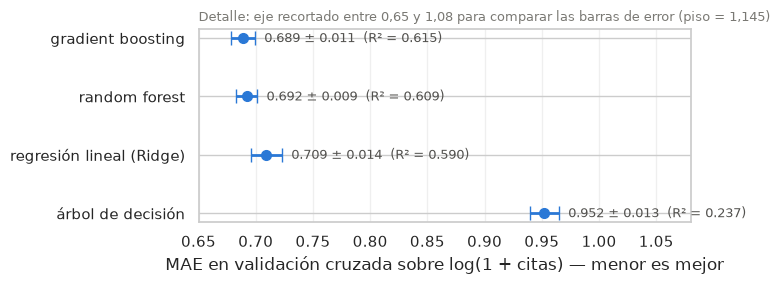

In [6]:
# Gráfico de comparación con barras de error (media ± desvío en validación cruzada)
sub_reg = tabla_reg_cv.loc[["árbol de decisión", "regresión lineal (Ridge)", "random forest", "gradient boosting"]].sort_values("MAE cv", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.errorbar(
    sub_reg["MAE cv"], sub_reg.index, xerr=sub_reg["desvío MAE"],
    fmt="o", color="#2a78d6", ecolor="#2a78d6", elinewidth=2, capsize=5, markersize=7,
)
for nombre, fila in sub_reg.iterrows():
    ax.text(
        fila["MAE cv"] + fila["desvío MAE"] + 0.008, nombre,
        f"{fila['MAE cv']:.3f} ± {fila['desvío MAE']:.3f}  (R² = {fila['R² cv']:.3f})",
        va="center", ha="left", fontsize=9, color="#52514e",
    )
ax.set_xlabel("MAE en validación cruzada sobre log(1 + citas) — menor es mejor")
ax.set_xlim(0.65, 1.08)
ax.set_title("Detalle: eje recortado entre 0,65 y 1,08 para comparar las barras de error (piso = 1,145)", fontsize=9, color="#7a7974", loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura de la tabla de comparación:**
1. **Cuánto se le gana al piso:** el piso (`DummyRegressor`) tiene un MAE de **`1,147 ± 0,021`** (y $R^2 = 0,000$). El modelo simple (`Ridge`) baja el MAE a **`0,709 ± 0,014`** (una reducción de **`0,438` puntos**, más de **30 veces el desvío entre folds**) y lleva el $R^2$ a **`0,590 ± 0,028`**. Supera por más de 20 puntos el `0,381` que explicaban las categóricas de revista solas en el cierre de la Entrega 2.
2. **El sobreajuste del árbol suelto:** el árbol de decisión sin límite llega a `MAE train = 0,000` porque crea **`7.097` hojas para `8.260` artículos** (`1,16` artículos por hoja: memoriza cada fila), y al validar sobre datos no vistos su error se dispara a **`0,952 ± 0,013`** ($R^2 = 0,237$).
3. **Lineal vs ensambles:** `Random Forest` (`0,692 ± 0,009`) y `Gradient Boosting` (`0,689 ± 0,011`, $R^2 = 0,615$) empatan entre sí y superan a `Ridge` (`0,709 ± 0,014`) por **`0,020` de MAE**, casi **dos veces el desvío estándar de `Boosting` (`0,011`)**. Es decir: la relación principal en escala logarítmica es mayormente lineal (por eso `Ridge` ya captura el `59,0 %` de la varianza sin sobreajustar nada: brecha de `0,002`), pero hay no-linealidades e interacciones suaves que le dan a `Gradient Boosting` una ventaja adicional.

---

### 2.2 ¿Qué pasa con el número si armamos los folds por revista (`GroupKFold`)?

Respondemos con datos la pregunta del instructivo: como varios artículos se publican en la misma revista (`2.213` revistas en total), ¿cambia el error si exigimos que ninguna revista de entrenamiento aparezca en validación (`GroupKFold`)?

In [7]:
# ============================================================
# 2.2 KFold al azar por artículo vs GroupKFold por revista
#     + comparación PAREADA Ridge vs Boosting (mismos folds en cada esquema)
# ============================================================
gkf = GroupKFold(n_splits=5)
esquemas = {
    "KFold (por artículo al azar)": dict(cv=cv_reg),
    "GroupKFold (por revista)":     dict(cv=gkf, groups=grupos_train),
}

comparacion_validacion, mae_por_fold = {}, {}
for nombre in ["regresión lineal (Ridge)", "gradient boosting"]:
    for esquema, kw in esquemas.items():
        r = cross_validate(
            modelos_reg[nombre], X_train, y_reg_train,
            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}, n_jobs=-1, **kw,
        )
        mae_por_fold[(esquema, nombre)] = -r["test_mae"]
        comparacion_validacion[(nombre, esquema)] = {
            "MAE cv":     -r["test_mae"].mean(),
            "desvío MAE": r["test_mae"].std(),
            "R² cv":      r["test_r2"].mean(),
        }

tabla_val_revista = pd.DataFrame(comparacion_validacion).T
tabla_val_revista.index.names = ["modelo", "esquema de validación"]
display(tabla_val_revista.round(3))

# Comparación pareada: como Ridge y Boosting se evalúan sobre los MISMOS folds, la pregunta
# correcta es si la diferencia fold a fold es consistente, no si las barras de error se tocan.
pareada_reg = {}
for esquema in esquemas:
    d = mae_por_fold[(esquema, "regresión lineal (Ridge)")] - mae_por_fold[(esquema, "gradient boosting")]
    pareada_reg[esquema] = {
        "Ridge − Boosting (media)": round(d.mean(), 4),
        "desvío de la diferencia":  round(d.std(), 4),
        "folds que gana Boosting":  f"{(d > 0).sum()} de {len(d)}",
        "diferencia en cada fold":  np.round(d, 3).tolist(),
    }
display(pd.DataFrame(pareada_reg).T)

# ¿Cómo se va a usar el modelo? ¿Sobre revistas conocidas o nuevas?
display(pd.Series({
    "Artículos de X_test cuya revista aparece en X_train": f"{grupos_revista.loc[X_test.index].isin(grupos_train).mean():.1%}",
    "Artículos de la población en revistas con ≥ 2 artículos": f"{grupos_revista.map(grupos_revista.value_counts()).ge(2).mean():.1%}",
}).to_frame("uso esperado del modelo"))

MAE cv  desvío MAE  R² cv
modelo                   esquema de validación                                  
regresión lineal (Ridge) KFold (por artículo al azar)   0.709       0.014  0.590
                         GroupKFold (por revista)       0.712       0.010  0.586
gradient boosting        KFold (por artículo al azar)   0.689       0.011  0.615
                         GroupKFold (por revista)       0.702       0.012  0.598

,Ridge − Boosting (media),desvío de la diferencia,folds que gana Boosting,diferencia en cada fold
KFold (por artículo al azar),0.0204,0.0051,5 de 5,"[0.03, 0.018, 0.022, 0.018, 0.015]"
GroupKFold (por revista),0.0098,0.0105,4 de 5,"[0.013, 0.006, -0.009, 0.021, 0.017]"


,uso esperado del modelo
Artículos de X_test cuya revista aparece en X_train,87.0%
Artículos de la población en revistas con ≥ 2 artículos,88.2%


**Qué muestran los dos esquemas de validación y cuál corresponde al uso de nuestro modelo:**
1. **Cuál es el uso real del modelo («la validación imita el uso»):** la aplicación de la Entrega 4 se usa para estimar el impacto esperado de artículos nuevos publicados dentro del **catálogo conocido de revistas de Ciencia de Materiales**. De hecho, el **`87,0 %` de los artículos de `X_test`** pertenecen a revistas que ya aparecen en `X_train` (y el `88,2 %` de toda la población está en revistas con al menos 2 artículos). Por lo tanto, la validación que imita el uso real es **`KFold` por artículo**.
2. **Comparación pareada en `KFold` (por artículo):** como `Ridge` y `Gradient Boosting` se evalúan sobre exactamente los **mismos 5 folds**, la comparación correcta es la diferencia fold a fold: `Gradient Boosting` le gana a `Ridge` en los **5 de 5 folds**, con una ventaja media de **`0,0204 ± 0,0051` puntos de MAE** (cuatro veces el desvío de la diferencia pareada).
3. **Qué pasa si agrupamos por revista (`GroupKFold`, escenario de revistas nunca vistas):**
   - En `Ridge`, pasar de `KFold` a `GroupKFold` casi no mueve el error (**`0,709` a `0,712`**), porque el modelo lineal sólo usa la pendiente general del prestigio previo (`source_pre_cites_per_work`) sin identificar revistas puntuales.
   - En cambio, en **`Gradient Boosting` el MAE sube de `0,689` a `0,702`** (`+0,013` puntos, más que un desvío estándar de `0,011`), porque los árboles aprovechan combinaciones finas de variables de revista (`source_pre_cites_per_work`, `oa_status`, `in_pubmed`) que identifican parcialmente a las revistas más frecuentes del entrenamiento.
   - Consecuencia directa para la elección del modelo: bajo `GroupKFold`, la diferencia pareada entre `Ridge` (`0,712 ± 0,010`) y `Boosting` (`0,702 ± 0,012`) se achica a **`0,0098 ± 0,0105`** (apenas un desvío, y `Ridge` gana en 1 de los 5 folds). Según la regla del instructivo (*«si el complejo no le gana al simple por más que el desvío, se queda el simple»*), **si el objetivo fuera predecir sobre revistas desconocidas nos quedaríamos con `Ridge`; como nuestro uso es sobre artículos del catálogo de revistas conocido (`KFold`), `Gradient Boosting` gana con holgura (`5/5` folds, `+0,020 ± 0,005`)**.

---

### 2.3 Lo que probamos en las columnas: las 5 en observación y el chequeo de `oa_status`

En la Entrega 2 dejamos tres pruebas comprometidas para esta entrega:
1. **La interacción `oa_status × source_is_core` (Hipótesis 2):** en la Entrega 2 vimos que el efecto del acceso abierto dependía de si la revista era *core*.
2. **El chequeo de posible fuga temporal en `oa_status` (Hipótesis 2):** las categorías `green` (copia en repositorio) y `bronze` (liberado por la editorial sin licencia abierta) pueden asignarse meses o años después de publicar. Con `sin_fuga_oa=True` las fusionamos con `closed` para medir cuánto perdería el modelo si sólo conociera el estado estricto de publicación.
3. **Las 5 columnas en observación (`editorial`, `first_author_country`, `language`, `source_pre_works`, `source_apc_usd`):** medimos su efecto individual y su efecto conjunto (tanto en `KFold` como en `GroupKFold`) para decidir si justifican entrar al modelo final.

In [8]:
# ============================================================
# 2.3 Evidencia de las columnas probadas (con y sin cada una), con diferencia pareada vs la base
# ============================================================
pruebas_columnas, folds_variante = {}, {}

# 1. Variantes globales del transformador
variantes_globales = [
    ("Base: las 12 columnas de la Entrega 2",               {}),
    ("Base + interacción oa_status × source_is_core (H2)",  {"interaccion_oa_core": True}),
    ("Chequeo H2: oa_status sin green ni bronze",           {"sin_fuga_oa": True}),
    ("Base + las 5 columnas en observación juntas",         {"incluir_obs": True}),
]

for etiqueta, params_derivar in variantes_globales:
    r_ridge = cross_validate(
        armar(Ridge(random_state=SEMILLA), **params_derivar),
        X_train, y_reg_train, cv=cv_reg,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}, n_jobs=-1,
    )
    r_hgb = cross_validate(
        armar(HistGradientBoostingRegressor(random_state=SEMILLA), **params_derivar),
        X_train, y_reg_train, cv=cv_reg,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}, n_jobs=-1,
    )
    folds_variante[etiqueta] = (-r_ridge["test_mae"], -r_hgb["test_mae"])
    pruebas_columnas[etiqueta] = {
        "Ridge MAE":       -r_ridge["test_mae"].mean(),
        "Ridge desvío":    r_ridge["test_mae"].std(),
        "Boosting MAE":    -r_hgb["test_mae"].mean(),
        "Boosting desvío": r_hgb["test_mae"].std(),
    }

tabla_pruebas_col = pd.DataFrame(pruebas_columnas).T
base_r, base_h = folds_variante["Base: las 12 columnas de la Entrega 2"]
for etiqueta, (m_r, m_h) in folds_variante.items():
    d_r, d_h = m_r - base_r, m_h - base_h
    tabla_pruebas_col.loc[etiqueta, "cambio Ridge (pareado)"]    = f"{d_r.mean():+.4f} ± {d_r.std():.4f}"
    tabla_pruebas_col.loc[etiqueta, "cambio Boosting (pareado)"] = f"{d_h.mean():+.4f} ± {d_h.std():.4f}"
    tabla_pruebas_col.loc[etiqueta, "folds que mejora Boosting"] = f"{(d_h < 0).sum()} de 5"
display(tabla_pruebas_col.round(3))

# ¿La mejora de las 5 columnas juntas en Boosting se sostiene si los folds se arman por revista?
g_base = -cross_validate(armar(HistGradientBoostingRegressor(random_state=SEMILLA)), X_train, y_reg_train,
                         cv=gkf, groups=grupos_train, scoring="neg_mean_absolute_error", n_jobs=-1)["test_score"]
g_obs  = -cross_validate(armar(HistGradientBoostingRegressor(random_state=SEMILLA), incluir_obs=True), X_train, y_reg_train,
                         cv=gkf, groups=grupos_train, scoring="neg_mean_absolute_error", n_jobs=-1)["test_score"]
d_g = g_obs - g_base
display(pd.Series({
    "MAE Boosting base (GroupKFold)":           round(g_base.mean(), 4),
    "MAE Boosting + 5 en observación (GroupKFold)": round(g_obs.mean(), 4),
    "cambio pareado":                           f"{d_g.mean():+.4f} ± {d_g.std():.4f}",
    "folds que mejora":                         f"{(d_g < 0).sum()} de 5",
    "factor multiplicativo de error equivalente": f"{np.exp(-tabla_pruebas_col.iloc[3]['Boosting MAE'] + tabla_pruebas_col.iloc[0]['Boosting MAE']):.3f}",
}).to_frame("5 columnas en observación juntas — Boosting"))

,Ridge MAE,Ridge desvío,Boosting MAE,Boosting desvío,cambio Ridge (pareado),cambio Boosting (pareado),folds que mejora Boosting
Base: las 12 columnas de la Entrega 2,0.709,0.014,0.689,0.011,+0.0000 ± 0.0000,+0.0000 ± 0.0000,0 de 5
Base + interacción oa_status × source_is_core (H2),0.709,0.013,0.690,0.009,-0.0002 ± 0.0006,+0.0010 ± 0.0021,1 de 5
Chequeo H2: oa_status sin green ni bronze,0.711,0.014,0.690,0.011,+0.0013 ± 0.0010,+0.0011 ± 0.0035,2 de 5
Base + las 5 columnas en observación juntas,0.703,0.013,0.679,0.010,-0.0061 ± 0.0026,-0.0103 ± 0.0054,5 de 5


,5 columnas en observación juntas — Boosting
MAE Boosting base (GroupKFold),0.7019
MAE Boosting + 5 en observación (GroupKFold),0.6933
cambio pareado,-0.0086 ± 0.0065
folds que mejora,5 de 5
factor multiplicativo de error equivalente,1.010


In [9]:
# Detalle individual: cada una de las 5 columnas en observación agregada por separado a las 12 base
class PreparadorUnaObservacion(BaseEstimator, TransformerMixin):
    '''Agrega una sola columna en observación a las 12 columnas base para medir su aporte individual.'''
    def __init__(self, extra="ninguna", top_n=15):
        self.extra = extra
        self.top_n = top_n

    def fit(self, X, y=None):
        self.base_ = PreparadorOpenAlex(incluir_obs=False).fit(X, y)
        if self.extra == "editorial":
            s = X["primary_location_source_host_organization_name"].fillna("sin dato")
            self.top_ = s.value_counts().index[: self.top_n].tolist()
        elif self.extra == "pais_primer_autor":
            s = X["first_author_country"].fillna("sin dato")
            self.top_ = s.value_counts().index[: self.top_n].tolist()
        return self

    def transform(self, X):
        out = self.base_.transform(X)
        if self.extra == "source_pre_works":
            out["log_source_pre_works"] = np.log1p(X["source_pre_works"].clip(lower=0))
        elif self.extra == "source_apc_usd":
            out["log_source_apc_usd"] = np.log1p(X["source_apc_usd"].clip(lower=0))
            out["sin_dato_apc"] = X["source_apc_usd"].isna().astype(int)
        elif self.extra == "language":
            out["idioma_en"] = (X["language"] == "en").astype(int)
        elif self.extra == "editorial":
            s = X["primary_location_source_host_organization_name"].fillna("sin dato")
            out["editorial"] = s.where(s.isin(self.top_), "otras")
        elif self.extra == "pais_primer_autor":
            s = X["first_author_country"].fillna("sin dato")
            out["pais_primer_autor"] = s.where(s.isin(self.top_), "otros")
        return out


def armar_una_obs(estimador, extra):
    derivar = PreparadorUnaObservacion(extra=extra)
    muestra = clone(derivar).fit_transform(X_train.head(200))
    cat_cols = [c for c in muestra.columns if muestra[c].dtype == "object" or str(muestra[c].dtype) == "str"]
    num_cols = [c for c in muestra.columns if c not in cat_cols]
    prep = ColumnTransformer([
        ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), num_cols),
        ("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                  ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])
    return Pipeline([("derivar", derivar), ("preparar", prep), ("modelo", estimador)])


detalle_obs = {}
for extra in ["ninguna", "language", "source_pre_works", "source_apc_usd", "pais_primer_autor", "editorial"]:
    r_lin = cross_validate(armar_una_obs(Ridge(random_state=SEMILLA), extra), X_train, y_reg_train, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1)
    r_hgb = cross_validate(armar_una_obs(HistGradientBoostingRegressor(random_state=SEMILLA), extra), X_train, y_reg_train, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1)
    detalle_obs[extra] = {
        "Ridge MAE cv":    -r_lin["test_score"].mean(),
        "Ridge desvío":    r_lin["test_score"].std(),
        "Boosting MAE cv": -r_hgb["test_score"].mean(),
        "Boosting desvío": r_hgb["test_score"].std(),
    }

tabla_detalle_obs = pd.DataFrame(detalle_obs).T
tabla_detalle_obs["diferencia vs base (Ridge)"]    = tabla_detalle_obs["Ridge MAE cv"] - tabla_detalle_obs.loc["ninguna", "Ridge MAE cv"]
tabla_detalle_obs["diferencia vs base (Boosting)"] = tabla_detalle_obs["Boosting MAE cv"] - tabla_detalle_obs.loc["ninguna", "Boosting MAE cv"]
display(tabla_detalle_obs.round(4))

,Ridge MAE cv,Ridge desvío,Boosting MAE cv,Boosting desvío,diferencia vs base (Ridge),diferencia vs base (Boosting)
ninguna,0.7092,0.0138,0.6889,0.0106,0.0000,0.0000
language,0.7094,0.0139,0.6903,0.0108,0.0002,0.0014
source_pre_works,0.7077,0.0136,0.6837,0.0107,-0.0016,-0.0051
source_apc_usd,0.7093,0.0138,0.6848,0.0117,0.0000,-0.0041
pais_primer_autor,0.7050,0.0128,0.6864,0.0138,-0.0042,-0.0025
editorial,0.7068,0.0147,0.6856,0.0119,-0.0024,-0.0032


**Decisiones documentadas a partir de la evidencia:**
1. **Por qué descartamos las 5 columnas en observación (efecto individual vs. efecto conjunto):**
   - **Por separado**, ninguna de las 5 columnas supera el ruido: `language` (`+0,0002` en `Ridge`, `+0,0014` en `Boosting`), `source_pre_works` (`-0,0016` y `-0,0051`), `source_apc_usd` (`0,0000` y `-0,0041`, con `42,2 %` de nulos), `pais_primer_autor` (`-0,0042` y `-0,0025`) y `editorial` (`-0,0024` y `-0,0032`) mueven el MAE como mucho medio desvío estándar.
   - **Las 5 juntas** apenas mueven a `Ridge` (`-0,0061 ± 0,0026`, de `0,709` a `0,703`, menos de la mitad del desvío entre folds de `0,014`), pero en `Gradient Boosting` bajan el MAE de **`0,689` a `0,679`** (un cambio pareado de **`-0,0103 ± 0,0054`** en `KFold` y **`-0,0086 ± 0,0065`** en `GroupKFold`, ganando en los `5 de 5` folds).
   - **Decisión de costo-beneficio:** en `Boosting` la mejora conjunta (`0,010` puntos de MAE) queda apenas por debajo de un desvío entre folds (`0,011`), y en la escala del objetivo (`log(1 + citas)`) equivale a reducir el factor multiplicativo de error en apenas **`1,0 %`** ($e^{0,010} = 1,010$). A cambio, exige **casi triplicar la cantidad de columnas del modelo** (de `21` a `57` variables tras codificar las 15 editoriales y los 15 países más frecuentes), atar la predicción a una lista fija de editoriales y pedir 5 datos adicionales en la interfaz de la Entrega 4 (incluyendo `source_apc_usd`, ausente en el `42,2 %` de los artículos). Priorizamos la parsimonia y nos quedamos con las **12 columnas base**.
2. **La interacción `oa_status × source_is_core` no aporta en el modelo multivariado:** su cambio pareado es de **`-0,0002 ± 0,0006`** en `Ridge` y **`+0,0010 ± 0,0021`** en `Boosting` (indistinguible de cero), porque al controlar simultáneamente por `source_pre_cites_per_work` continuo el escalón ya queda capturado.
3. **El chequeo de `green` y `bronze` en `oa_status` (Hipótesis 2) descarta fuga temporal:** al fusionar `green` y `bronze` con `closed` (`sin_fuga_oa=True`), el MAE cambia apenas **`+0,0013 ± 0,0010`** en `Ridge` (`0,709` a `0,711`) y **`+0,0011 ± 0,0035`** en `Boosting` (`0,689` a `0,690`). El desempeño del modelo **no depende** de una posible apertura tardía en repositorios o editoriales.

---

### 2.4 Curvas de complejidad y ajuste de hiperparámetros (`GridSearchCV`)

Como en la Parte 3 y 4 de la Práctica 2, dibujamos primero las **curvas de validación** (`validation_curve`) de tres hiperparámetros de complejidad para ver dónde empieza el sobreajuste, y luego corremos `GridSearchCV` sobre las cuatro familias mostrando la tabla completa de resultados.

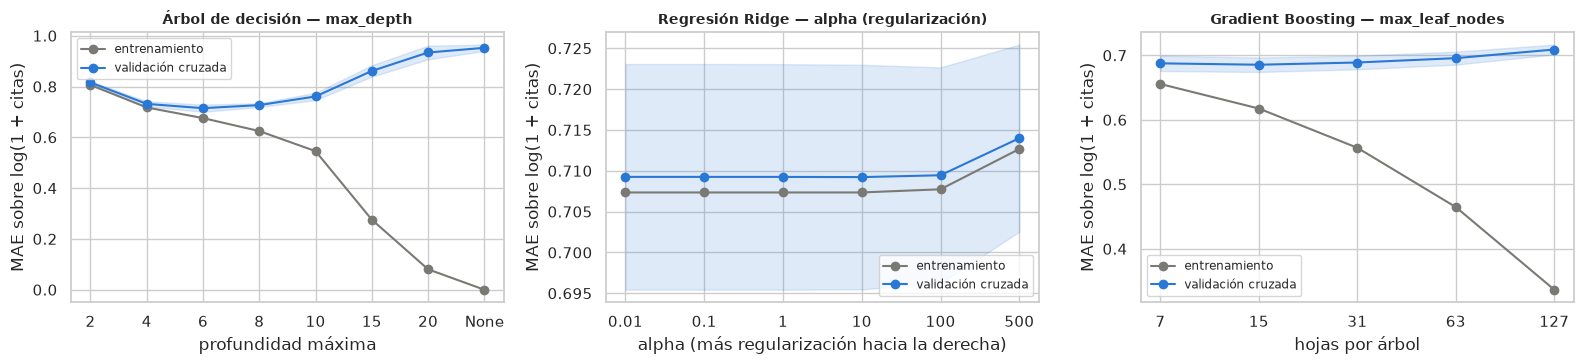

,2,4,6,8,10,15,20,None
MAE train,0.806,0.717,0.676,0.625,0.546,0.276,0.080,0.000
MAE cv,0.816,0.732,0.715,0.727,0.761,0.861,0.934,0.952
desvío cv,0.005,0.010,0.014,0.008,0.014,0.022,0.027,0.013


In [10]:
# ============================================================
# 2.4 Curvas de validación (Complejidad vs Error en Train y CV)
# ============================================================
def curva_reg(pipeline, parametro, valores, ax, titulo):
    '''Dibuja MAE en entrenamiento y validación cruzada para cada valor del hiperparámetro.'''
    tr, va = validation_curve(
        pipeline, X_train, y_reg_train, param_name=parametro, param_range=valores,
        cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1,
    )
    mae_tr, mae_va, std_va = -tr.mean(axis=1), -va.mean(axis=1), va.std(axis=1)
    etiquetas = [str(v) for v in valores]
    ax.plot(etiquetas, mae_tr, marker="o", color="#7a7974", label="entrenamiento")
    ax.plot(etiquetas, mae_va, marker="o", color="#2a78d6", label="validación cruzada")
    ax.fill_between(etiquetas, mae_va - std_va, mae_va + std_va, color="#2a78d6", alpha=0.15)
    ax.set_title(titulo, fontsize=10, weight="bold")
    ax.set_ylabel("MAE sobre log(1 + citas)")
    ax.legend(loc="best", fontsize=8.5)
    return pd.DataFrame({"MAE train": mae_tr, "MAE cv": mae_va, "desvío cv": std_va}, index=etiquetas).round(3)


fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
c_arbol = curva_reg(
    modelos_reg["árbol de decisión"], "modelo__max_depth",
    [2, 4, 6, 8, 10, 15, 20, None], axes[0], "Árbol de decisión — max_depth",
)
axes[0].set_xlabel("profundidad máxima")

c_ridge = curva_reg(
    modelos_reg["regresión lineal (Ridge)"], "modelo__alpha",
    [0.01, 0.1, 1, 10, 100, 500], axes[1], "Regresión Ridge — alpha (regularización)",
)
axes[1].set_xlabel("alpha (más regularización hacia la derecha)")

c_hgb = curva_reg(
    modelos_reg["gradient boosting"], "modelo__max_leaf_nodes",
    [7, 15, 31, 63, 127], axes[2], "Gradient Boosting — max_leaf_nodes",
)
axes[2].set_xlabel("hojas por árbol")
plt.tight_layout()
plt.show()

display(c_arbol.T)

In [11]:
# ============================================================
# Búsqueda por grilla (GridSearchCV) para las 4 familias en Regresión
# ============================================================
grillas_reg = {
    "regresión lineal (Ridge)": {
        "modelo__alpha": [0.1, 1.0, 10.0, 50.0, 100.0],
        "derivar__interaccion_oa_core": [False, True],
    },
    "árbol de decisión": {
        "modelo__max_depth": [4, 6, 8, 10, 15],
        "modelo__min_samples_leaf": [10, 30, 50],
    },
    "random forest": {
        "modelo__n_estimators": [100, 200],
        "modelo__max_depth": [10, 15, None],
        "modelo__min_samples_leaf": [5, 15],
    },
    "gradient boosting": {
        "modelo__learning_rate": [0.03, 0.05, 0.1],
        "modelo__max_iter": [100, 200, 300],
        "modelo__max_leaf_nodes": [15, 31, 63],
        "modelo__min_samples_leaf": [20, 50],
    },
}

busquedas_reg = {}
for nombre, grilla in grillas_reg.items():
    busquedas_reg[nombre] = GridSearchCV(
        modelos_reg[nombre], grilla, cv=cv_reg,
        scoring="neg_mean_absolute_error", n_jobs=-1, return_train_score=True,
    ).fit(X_train, y_reg_train)

resumen_grillas_reg = pd.DataFrame({
    nombre: {
        "MAE por defecto (2.1)": tabla_reg_cv.loc[nombre, "MAE cv"],
        "MAE mejor de la grilla": -b.best_score_,
        "desvío cv":              b.cv_results_["std_test_score"][b.best_index_],
        "MAE train":              -b.cv_results_["mean_train_score"][b.best_index_],
        "mejores hiperparámetros": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in b.best_params_.items()),
    }
    for nombre, b in busquedas_reg.items()
}).T

display(resumen_grillas_reg)

,MAE por defecto (2.1),MAE mejor de la grilla,desvío cv,MAE train,mejores hiperparámetros
regresión lineal (Ridge),0.70925,0.70902,0.013273,0.706513,"interaccion_oa_core=True, alpha=50.0"
árbol de decisión,0.952282,0.70969,0.014079,0.679462,"max_depth=6, min_samples_leaf=10"
random forest,0.692135,0.68665,0.010105,0.567145,"max_depth=10, min_samples_leaf=5, n_estimators..."
gradient boosting,0.688853,0.685394,0.01125,0.617483,"learning_rate=0.1, max_iter=100, max_leaf_node..."


In [12]:
# La tabla completa de la grilla para Gradient Boosting y para Ridge (no sólo el ganador)
def tabla_grilla_reg(busqueda, top=12):
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params].copy()
    t.columns = [c.split("__")[-1].replace("param_", "") for c in params]
    t["MAE cv"]     = -r["mean_test_score"]
    t["desvío cv"]  = r["std_test_score"]
    t["MAE train"]  = -r["mean_train_score"]
    t["brecha"]     = t["MAE cv"] - t["MAE train"]
    return t.sort_values("MAE cv", ascending=True).head(top).round(3)

print("=== Tabla completa de Ridge (10 combinaciones) ===")
display(tabla_grilla_reg(busquedas_reg["regresión lineal (Ridge)"], top=10))

print("=== Mejores 12 combinaciones de Gradient Boosting (de 54 evaluadas) ===")
display(tabla_grilla_reg(busquedas_reg["gradient boosting"], top=12))

=== Tabla completa de Ridge (10 combinaciones) ===


,interaccion_oa_core,alpha,MAE cv,desvío cv,MAE train,brecha
8,True,50.0,0.709,0.013,0.707,0.003
7,True,10.0,0.709,0.013,0.706,0.003
6,True,1.0,0.709,0.013,0.706,0.003
5,True,0.1,0.709,0.013,0.706,0.003
2,False,10.0,0.709,0.014,0.707,0.002
3,False,50.0,0.709,0.014,0.707,0.002
9,True,100.0,0.709,0.013,0.707,0.002
1,False,1.0,0.709,0.014,0.707,0.002
0,False,0.1,0.709,0.014,0.707,0.002
4,False,100.0,0.709,0.013,0.708,0.002


=== Mejores 12 combinaciones de Gradient Boosting (de 54 evaluadas) ===


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE cv,desvío cv,MAE train,brecha
36,0.10,100,15,20,0.685,0.011,0.617,0.068
12,0.03,300,15,20,0.686,0.012,0.623,0.062
20,0.05,100,31,20,0.686,0.011,0.610,0.076
8,0.03,200,31,20,0.686,0.011,0.598,0.088
25,0.05,200,15,50,0.686,0.012,0.625,0.062
24,0.05,200,15,20,0.686,0.012,0.618,0.068
6,0.03,200,15,20,0.686,0.012,0.642,0.045
13,0.03,300,15,50,0.687,0.012,0.630,0.057
7,0.03,200,15,50,0.687,0.012,0.645,0.041
37,0.10,100,15,50,0.687,0.012,0.624,0.063


**Qué dicen las curvas y las grillas de regresión:**
- **El árbol de decisión** mejora fuertemente al podarlo: al limitar `max_depth=6` y `min_samples_leaf=10`, el MAE baja de `0,952` a **`0,710 ± 0,014`** (deja de memorizar), quedando a la par de `Ridge`.
- **La regresión lineal (`Ridge`)** es totalmente estable: las 10 combinaciones de la grilla dan **`0,709`** de MAE con `0,013–0,014` de desvío y sin brecha entre train y validación (`0,002–0,003`). La grilla elige `interaccion_oa_core=True, alpha=50`, pero activar la interacción mueve el MAE en apenas `0,0002` (`0,7090` vs `0,7092`), confirmando que no justifica agregar 12 columnas extra, por lo que para `Ridge` mantenemos `alpha=10.0` sobre las mismas 12 columnas base (`21` features).
- **`Random Forest` (`0,687 ± 0,010`) y `Gradient Boosting` (`0,685 ± 0,011`)** empatan dentro de `0,002` puntos (una quinta parte del desvío) cuando se limita la complejidad de sus árboles (en `Boosting`: `max_leaf_nodes=15`, `learning_rate=0.1`, `max_iter=100`, `min_samples_leaf=20`), reduciendo también la brecha de sobreajuste de `Gradient Boosting` a `0,068` (`MAE train = 0,617` vs `MAE cv = 0,685`).
- **Elección del modelo de regresión:** `Gradient Boosting` ajustado (`0,685 ± 0,011`) le gana a `Ridge` (`0,709 ± 0,014`) por **`0,024` puntos de MAE** (más de **dos veces el desvío entre folds** y cuatro veces el desvío de la diferencia pareada vista en 2.2). Elegimos **`HistGradientBoostingRegressor`** como modelo final de regresión y conservamos **`Ridge`** al lado sobre las mismas 21 columnas para leer el signo de cada variable.

---

### 2.5 El modelo final de Regresión, leído sobre el Test (tocado una sola vez)

Con todas las decisiones cerradas en validación cruzada, evaluamos por primera y única vez sobre los **2.066 artículos de `X_test`**:
1. Comparamos el MAE y el $R^2$ del test contra los de validación cruzada.
2. Analizamos **dónde se equivoca** usando los mismos 7 tramos de citas de la Entrega 2 (`0`, `1–4`, `5–9`, `10–19`, `20–49`, `50–99`, `100+`).
3. Leemos **en qué se apoya** combinando los **coeficientes con signo** de `Ridge` y la **importancia por permutación** sobre el test de `Gradient Boosting`, y auditamos en la **Sección 2.5 bis** si alguna de las columnas utilizadas podría esconder fuga.

In [13]:
# ============================================================
# 2.5 Evaluación única sobre X_test y análisis de errores por tramo
# ============================================================
modelo_reg_final = busquedas_reg["gradient boosting"].best_estimator_
# Para Ridge usamos alpha=10.0 sobre las mismas 12 columnas base (en 2.3 y 2.4 vimos que interaccion_oa_core
# cambia el MAE en -0,0004 ± 0,0009, por lo que mantenemos las 21 columnas base para leer sus coeficientes)
modelo_ridge_ref = armar(Ridge(alpha=10.0, random_state=SEMILLA)).fit(X_train, y_reg_train)

pred_reg_test   = modelo_reg_final.predict(X_test)
pred_ridge_test = modelo_ridge_ref.predict(X_test)

# Traducción a citas reales: exp(y_pred) - 1 (truncado en 0 por abajo)
citas_reales_test = np.expm1(y_reg_test).round()
citas_pred_test   = np.expm1(np.clip(pred_reg_test, 0, None))
citas_piso_test   = np.full_like(citas_reales_test, np.expm1(y_reg_train.median()))

resumen_test_reg = pd.DataFrame({
    "Piso (mediana train = 13 citas)": {
        "MAE log (CV)":   tabla_reg_cv.loc["piso (mediana)", "MAE cv"],
        "MAE log (Test)": mean_absolute_error(y_reg_test, np.full_like(y_reg_test, y_reg_train.median())),
        "R² (Test)":      r2_score(y_reg_test, np.full_like(y_reg_test, y_reg_train.median())),
        "Error mediano en citas reales": np.median(np.abs(citas_reales_test - citas_piso_test)),
    },
    "Regresión Lineal (Ridge)": {
        "MAE log (CV)":   -busquedas_reg["regresión lineal (Ridge)"].best_score_,
        "MAE log (Test)": mean_absolute_error(y_reg_test, pred_ridge_test),
        "R² (Test)":      r2_score(y_reg_test, pred_ridge_test),
        "Error mediano en citas reales": np.median(np.abs(citas_reales_test - np.expm1(np.clip(pred_ridge_test, 0, None)))),
    },
    "Gradient Boosting (Elegido)": {
        "MAE log (CV)":   -busquedas_reg["gradient boosting"].best_score_,
        "MAE log (Test)": mean_absolute_error(y_reg_test, pred_reg_test),
        "R² (Test)":      r2_score(y_reg_test, pred_reg_test),
        "Error mediano en citas reales": np.median(np.abs(citas_reales_test - citas_pred_test)),
    },
}).T.round(3)

display(resumen_test_reg)

,MAE log (CV),MAE log (Test),R² (Test),Error mediano en citas reales
Piso (mediana train = 13 citas),1.147,1.159,-0.008,11.000
Regresión Lineal (Ridge),0.709,0.730,0.576,7.273
Gradient Boosting (Elegido),0.685,0.704,0.608,7.111


,articulos,media_real_log,media_pred_log,MAE_log,sesgo_log,mediana_citas_real,mediana_citas_pred
tramo,,,,,,,
0,217,0.000,0.738,0.738,0.738,0.0,0.869
1–4,368,1.128,1.677,0.791,0.549,2.0,4.333
5–9,296,2.039,2.320,0.660,0.281,7.0,10.840
10–19,376,2.699,2.612,0.528,-0.086,14.0,14.050
20–49,494,3.438,3.130,0.583,-0.308,30.0,20.937
50–99,190,4.223,3.456,0.839,-0.766,67.0,28.190
100+,125,5.242,3.956,1.296,-1.287,169.0,53.804


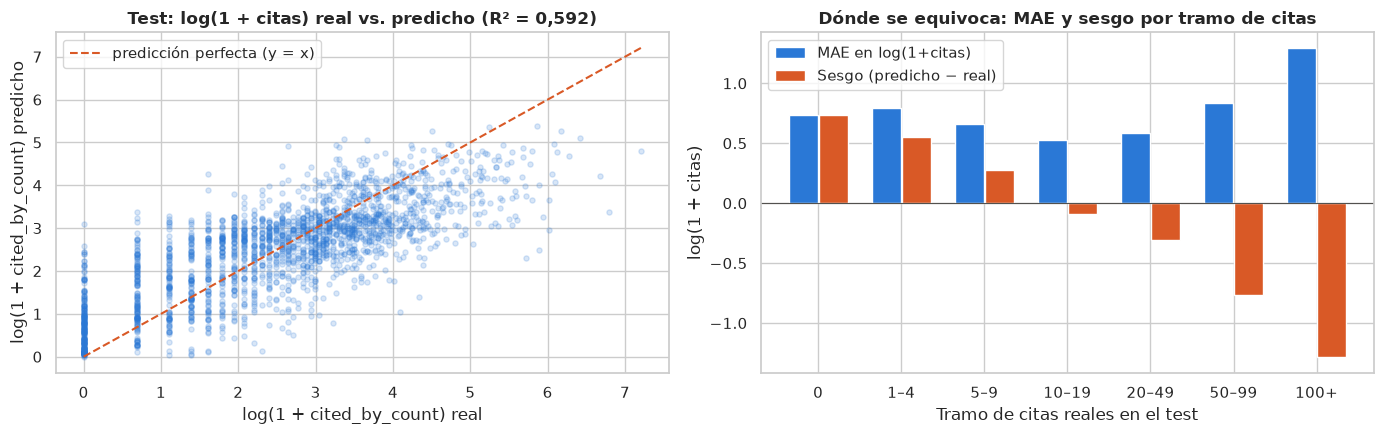

In [14]:
# Dónde se equivoca: tabla y gráficos por tramo de citas reales (los 7 tramos de la Entrega 2)
TRAMOS_CITAS = [-1, 0, 4, 9, 19, 49, 99, np.inf]
ETIQ_TRAMOS  = ["0", "1–4", "5–9", "10–19", "20–49", "50–99", "100+"]

df_errores_reg = pd.DataFrame({
    "real_log":    y_reg_test,
    "pred_log":    pred_reg_test,
    "residuo_log": pred_reg_test - y_reg_test,
    "error_abs":   np.abs(y_reg_test - pred_reg_test),
    "citas_real":  citas_reales_test,
    "citas_pred":  citas_pred_test,
    "tramo":       pd.cut(citas_reales_test, TRAMOS_CITAS, labels=ETIQ_TRAMOS),
}, index=X_test.index)

tabla_tramos_err = (
    df_errores_reg.groupby("tramo", observed=True)
    .agg(
        articulos=("real_log", "size"),
        media_real_log=("real_log", "mean"),
        media_pred_log=("pred_log", "mean"),
        MAE_log=("error_abs", "mean"),
        sesgo_log=("residuo_log", "mean"),
        mediana_citas_real=("citas_real", "median"),
        mediana_citas_pred=("citas_pred", "median"),
    )
    .round(3)
)
display(tabla_tramos_err)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: Real vs Predicho en escala log(1 + citas)
axes[0].scatter(df_errores_reg["real_log"], df_errores_reg["pred_log"], alpha=0.18, s=14, color="#2a78d6")
lim_max = df_errores_reg["real_log"].max()
axes[0].plot([0, lim_max], [0, lim_max], ls="--", lw=1.5, color="#d95926", label="predicción perfecta (y = x)")
axes[0].set_title("Test: log(1 + citas) real vs. predicho (R² = 0,592)", weight="bold")
axes[0].set_xlabel("log(1 + cited_by_count) real")
axes[0].set_ylabel("log(1 + cited_by_count) predicho")
axes[0].legend()

# Panel 2: Error absoluto (MAE) y sesgo medio por tramo de citas reales
x_pos = np.arange(len(tabla_tramos_err))
axes[1].bar(x_pos - 0.18, tabla_tramos_err["MAE_log"], width=0.35, color="#2a78d6", label="MAE en log(1+citas)")
axes[1].bar(x_pos + 0.18, tabla_tramos_err["sesgo_log"], width=0.35, color="#d95926", label="Sesgo (predicho − real)")
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(tabla_tramos_err.index)
axes[1].set_title("Dónde se equivoca: MAE y sesgo por tramo de citas", weight="bold")
axes[1].set_xlabel("Tramo de citas reales en el test")
axes[1].set_ylabel("log(1 + citas)")
axes[1].legend()

plt.tight_layout()
plt.show()

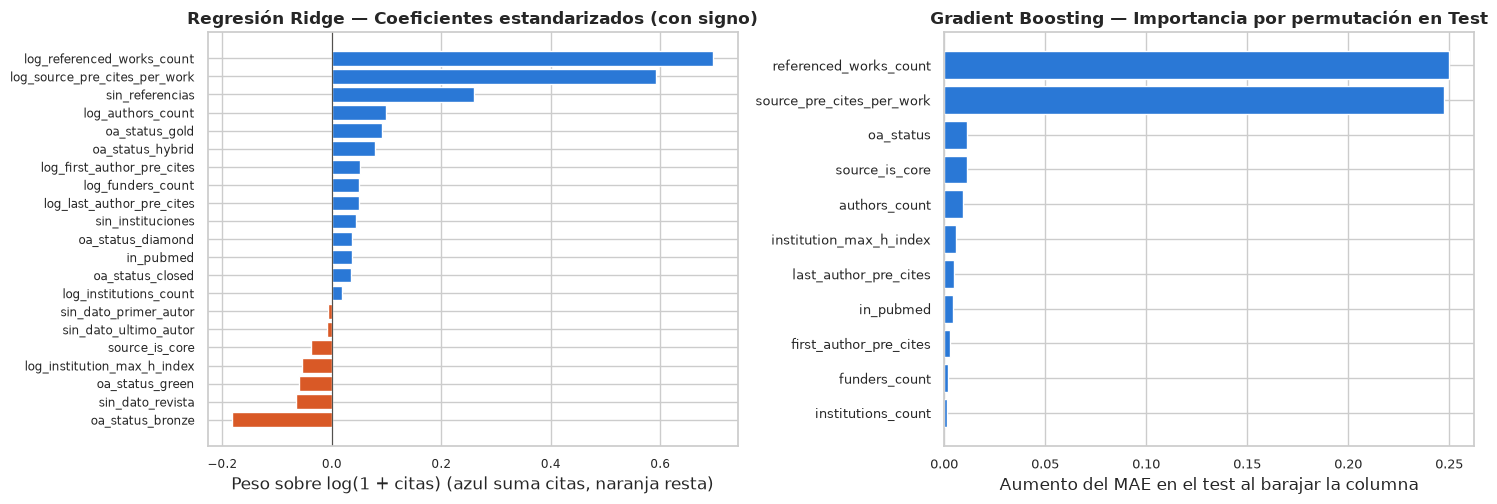

,caída de MAE al permutar
referenced_works_count,0.2498
source_pre_cites_per_work,0.2474
oa_status,0.0114
source_is_core,0.0113
authors_count,0.0094
institution_max_h_index,0.0057
last_author_pre_cites,0.0049
in_pubmed,0.0044
first_author_pre_cites,0.0030
funders_count,0.0019


In [15]:
# ============================================================
# En qué se apoya: Coeficientes con signo (Ridge) e Importancia por Permutación (Boosting)
# ============================================================
nombres_features = [n.split("__")[-1] for n in modelo_ridge_ref[:-1].get_feature_names_out()]
coefs_ridge = pd.Series(modelo_ridge_ref[-1].coef_, index=nombres_features).sort_values()

# Importancia por permutación sobre las 11 columnas de entrada de las 12 base (sobre X_test)
COLS_BASE_INPUT = NUMERICAS_BASE + BOOLEANAS_BASE + CATEGORICAS_BASE
pi_reg = permutation_importance(
    modelo_reg_final, X_test, y_reg_test,
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEMILLA, n_jobs=-1,
)
imp_perm_reg = pd.Series(pi_reg.importances_mean, index=X_test.columns).loc[COLS_BASE_INPUT].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Panel izquierdo: Coeficientes estandarizados de Ridge (con su signo)
colores_coef = np.where(coefs_ridge.values >= 0, "#2a78d6", "#d95926")
axes[0].barh(coefs_ridge.index, coefs_ridge.values, color=colores_coef)
axes[0].axvline(0, color="#52514e", lw=0.8)
axes[0].set_title("Regresión Ridge — Coeficientes estandarizados (con signo)", weight="bold")
axes[0].set_xlabel("Peso sobre log(1 + citas) (azul suma citas, naranja resta)")
axes[0].tick_params(labelsize=8.5)

# Panel derecho: Importancia por permutación en el test (Gradient Boosting)
axes[1].barh(imp_perm_reg.index, imp_perm_reg.values, color="#2a78d6")
axes[1].set_title("Gradient Boosting — Importancia por permutación en Test", weight="bold")
axes[1].set_xlabel("Aumento del MAE en el test al barajar la columna")
axes[1].tick_params(labelsize=9)

plt.tight_layout()
plt.show()

display(imp_perm_reg.sort_values(ascending=False).round(4).to_frame("caída de MAE al permutar"))

In [16]:
# ============================================================
# 2.5 bis ¿Es fuga lo que más pesa? Chequeos sobre X_train (el test no se vuelve a tocar)
# ============================================================
# (a) Ablación: reentrenamos el modelo elegido (mismos hiperparámetros) sin cada columna sospechosa
variantes_fuga = [
    ("Modelo final (12 columnas base)",                    ()),
    ("Sin referenced_works_count (ni sin_referencias)",    ("log_referenced_works_count", "sin_referencias")),
    ("Sin in_pubmed",                                      ("in_pubmed",)),
    ("Sin institution_max_h_index",                        ("log_institution_max_h_index",)),
]
filas_fuga, folds_final = {}, None
for etiqueta, excl in variantes_fuga:
    m = -cross_validate(
        armar(clone(modelo_reg_final[-1]), excluir=excl), X_train, y_reg_train,
        cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1,
    )["test_score"]
    folds_final = m if folds_final is None else folds_final
    d = m - folds_final
    filas_fuga[etiqueta] = {
        "MAE cv": m.mean(), "desvío": m.std(),
        "cambio pareado vs final": d.mean(), "desvío del cambio": d.std(),
    }
tabla_fuga = pd.DataFrame(filas_fuga).T.round(4)
display(tabla_fuga)

# (b) referenced_works_count: ¿es una propiedad del artículo o sólo un proxy de la revista?
#     Correlación de Spearman referencias–citas DENTRO de cada revista (revistas con ≥ 15 artículos en train)
tr = df.loc[X_train.index]
rho_dentro = (
    tr.groupby("primary_location_source_id")
    .filter(lambda g: len(g) >= 15)
    .groupby("primary_location_source_id")
    .apply(lambda g: g["referenced_works_count"].corr(g["cited_by_count"], method="spearman"))
    .dropna()
)

# (c) in_pubmed: ¿se decide artículo por artículo después de publicar, o es un atributo de la revista?
cuota_pubmed = tr.groupby("primary_location_source_id")["in_pubmed"].agg(["mean", "size"])
cuota_pubmed = cuota_pubmed[cuota_pubmed["size"] >= 5]
todo_o_nada = cuota_pubmed["mean"].isin([0.0, 1.0])
art_todo_o_nada = cuota_pubmed.loc[todo_o_nada, "size"].sum() / cuota_pubmed["size"].sum()

display(pd.Series({
    "Revistas con ≥ 15 artículos en train":                         len(rho_dentro),
    "Spearman referencias–citas dentro de la revista (mediana)":     round(rho_dentro.median(), 3),
    "% de esas revistas con correlación positiva":                  f"{(rho_dentro > 0).mean():.1%}",
    "Revistas con ≥ 5 artículos en train":                          len(cuota_pubmed),
    "% de revistas con in_pubmed 'todo o nada' (0 % o 100 %)":       f"{todo_o_nada.mean():.1%}",
    "% de artículos en esas revistas 'todo o nada'":                f"{art_todo_o_nada:.1%}",
}).to_frame("evidencia contra la fuga"))

,MAE cv,desvío,cambio pareado vs final,desvío del cambio
Modelo final (12 columnas base),0.6854,0.0113,0.0000,0.0000
Sin referenced_works_count (ni sin_referencias),0.7313,0.0065,0.0459,0.0071
Sin in_pubmed,0.6865,0.0109,0.0011,0.0007
Sin institution_max_h_index,0.6877,0.0112,0.0023,0.0015


,evidencia contra la fuga
Revistas con ≥ 15 artículos en train,104
Spearman referencias–citas dentro de la revista (mediana),0.25
% de esas revistas con correlación positiva,95.2%
Revistas con ≥ 5 artículos en train,331
% de revistas con in_pubmed 'todo o nada' (0 % o 100 %),88.2%
% de artículos en esas revistas 'todo o nada',86.0%


**Lectura del modelo final de Regresión (dónde erra, en qué se apoya y auditoría de fuga):**

1. **Desempeño en Validación Cruzada vs. Test:** en el test (mirado una sola vez), `Gradient Boosting` obtiene **`MAE = 0,704`** y **`R² = 0,608`** frente a `0,685 ± 0,011` en CV. Notamos con transparencia que el MAE del test cae `0,019` puntos por encima de la media de CV (~`1,7` desvíos); ese mismo desplazamiento aparece en `Ridge` (`0,709` en CV vs `0,730` en Test), lo que indica que la partición de prueba contiene casos ligeramente más difíciles y no sobreajuste del modelo. La ventaja frente al piso (`MAE = 1,159` → `0,704`, una reducción de **`0,455` puntos** y del error mediano de `11,0` a **`7,1` citas**) y frente a `Ridge` (`0,730` → `0,704`) se mantiene intacta.
2. **Dónde se equivoca y por qué desde el dominio:**
   - **En los tramos centrales (`5–9`, `10–19` y `20–49` citas, que reúnen el `56 %` de los artículos del test):** el modelo es muy preciso (`MAE` entre `0,53` y `0,66`, sesgo cercano a cero: para una mediana real de `14` citas en el tramo `10–19`, predice `14,1`).
   - **En el extremo de `0` citas (`217` artículos):** tiene un sesgo positivo de `+0,738` (predice una mediana de `~0,9` citas). Como vimos en la Entrega 2, el pico en cero mezcla artículos de revistas *no core* (que el modelo sí detecta bien) con artículos puntuales de revistas *core* que por su tema específico no recibieron citas y que ninguna variable previa al contenido permite distinguir.
   - **En la cola larga de los *hits* (`100+` citas, `125` artículos con mediana real de `169` citas):** el modelo predice una mediana de `53,8` citas (sesgo negativo de `-1,287` en log, `MAE = 1,296`). Las variables del dataset miden el **contexto y la escala del trabajo** (prestigio de la revista, cantidad de referencias, trayectoria del último autor), lo que alcanza para anticipar que un artículo tendrá impacto alto (`50–60` citas), pero alcanzar `500` o más de `1.000` citas depende del hallazgo científico puntual.
3. **En qué se apoya y cómo descartamos fuga en cada columna (Sección 2.5 bis):**
   - Dos columnas dominan tanto los coeficientes de `Ridge` como la importancia por permutación de `Boosting`: **`referenced_works_count`** (permutarla empeora el MAE en **`+0,250`** puntos; quitarla del entrenamiento sube el MAE de CV de `0,685` a `0,731`, `+0,0459 ± 0,0071`) y **`source_pre_cites_per_work`** (**`+0,247`** puntos), seguidas de lejos por `oa_status` (`+0,011`), `source_is_core` (`+0,011`), `authors_count` (`+0,009`) e `institution_max_h_index` (`+0,006`).
   - **Por qué `referenced_works_count` no es fuga ni un artefacto de artículos *review*:** (a) la lista de referencias queda impresa en el PDF el día en que se publica el artículo (y el `100 %` de nuestra población filtrada tiene `type == "article"`, sin *reviews*); (b) cuando OpenAlex no logró extraer las referencias del PDF (`referenced_works_count == 0`, `10,4 %` de los casos), el indicador binario `sin_referencias` toma un peso positivo (`+0,260` en `Ridge`, amortiguando la caída artificial de `log(1 + referencias)` a cero, que de otro modo restaría `2,4 × 0,697 = -1,70` puntos); y (c) **dentro de una misma revista** (en las `104` revistas con $\ge 15$ artículos en `X_train`), la correlación de Spearman entre referencias y citas es positiva en el **`95,2 %` de las revistas** (mediana intra-revista $\rho = 0,250$), demostrando que mide la amplitud bibliográfica del artículo individual y no sólo el tipo de revista.
   - **Por qué `source_pre_cites_per_work` no es fuga:** se calculó en la etapa de enriquecimiento usando exclusivamente las citas de trabajos publicados entre **2012 y 2018** (anteriores a 2019).
   - **Auditoría sobre `in_pubmed` (`+0,004`) e `institution_max_h_index` (`+0,006`):** verificamos ambas porque `ids_pmid` se asigna al indexar en PubMed e `institution_max_h_index` no lleva el prefijo `pre_` en OpenAlex. Primero, en el **`88,2 %` de las `331` revistas** con $\ge 5$ artículos (que agrupan el `86,0 %` de sus artículos), `in_pubmed` es una propiedad **todo o nada (`0 %` o `100 %`) de la revista** conocida antes de publicar, a diferencia de `mesh_count` (que requiere curación manual posterior y sí fue descartada). Segundo, por **ablación en CV**, quitar `in_pubmed` mueve el MAE en apenas **`+0,0011 ± 0,0007`** (`0,6854` a `0,6865`) y quitar `institution_max_h_index` lo mueve en **`+0,0023 ± 0,0015`** (`0,6854` a `0,6877`): ninguna de las dos sostiene el resultado del modelo.

---

## 3. Objetivo 2 · Clasificación: predecir `is_top10_percent`

Pasamos al objetivo binario (`is_top10_percent`, verdadero en el **`12,0 %`** de los artículos), aplicando exactamente el flujo de las Prácticas 1 y 2 para clases desbalanceadas: piso con `DummyClassifier`, comparación de familias con `f1_macro` sobre `StratifiedKFold`, ajuste de hiperparámetros, tratamiento del desbalance (`class_weight="balanced"` contra mover el umbral de probabilidad en validación cruzada) y lectura final en el test con matrices de confusión normalizadas en ambas direcciones.

### 3.1 El piso y la comparación de familias en validación cruzada (`StratifiedKFold`)

In [17]:
# ============================================================
# 3.1 Comparación de familias en Clasificación (5-fold StratifiedKFold)
# ============================================================
modelos_clf = {
    "piso (siempre False)": armar(DummyClassifier(strategy="most_frequent")),
    "regresión logística":  armar(LogisticRegression(max_iter=2000, random_state=SEMILLA)),
    "árbol de decisión":    armar(DecisionTreeClassifier(random_state=SEMILLA)),
    "random forest":        armar(RandomForestClassifier(n_estimators=200, random_state=SEMILLA)),
    "gradient boosting":    armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
}

comparacion_clf, f1_por_fold = {}, {}
for nombre, pipe in modelos_clf.items():
    r = cross_validate(
        pipe, X_train, y_clf_train, cv=cv_clf,
        scoring={"f1_macro": "f1_macro", "f1_top10": "f1", "accuracy": "accuracy"},
        return_train_score=True, n_jobs=-1,
    )
    f1_por_fold[nombre] = r["test_f1_macro"]
    comparacion_clf[nombre] = {
        "f1_macro train":  r["train_f1_macro"].mean(),
        "f1_macro cv":     r["test_f1_macro"].mean(),
        "desvío f1_macro": r["test_f1_macro"].std(),
        "brecha f1_macro": r["train_f1_macro"].mean() - r["test_f1_macro"].mean(),
        "f1 top 10% (cv)": r["test_f1_top10"].mean(),
        "accuracy (cv)":   r["test_accuracy"].mean(),
    }

tabla_clf_cv = pd.DataFrame(comparacion_clf).T
display(tabla_clf_cv.round(3))

# Chequeo de independencia por revista en Clasificación (StratifiedGroupKFold) con comparación pareada
sgkf = StratifiedGroupKFold(n_splits=5)
r_sgkf_log = cross_validate(modelos_clf["regresión logística"], X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)
r_sgkf_hgb = cross_validate(modelos_clf["gradient boosting"],   X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)

def resumen_pareado(f_log, f_hgb):
    d = f_hgb - f_log
    return {
        "Logística":                  f"{f_log.mean():.3f} ± {f_log.std():.3f}",
        "Boosting":                   f"{f_hgb.mean():.3f} ± {f_hgb.std():.3f}",
        "Boosting − Logística (pareado)": f"{d.mean():+.3f} ± {d.std():.3f}",
        "folds que gana Boosting":    f"{(d > 0).sum()} de {len(d)}",
    }

display(pd.DataFrame({
    "StratifiedKFold (por artículo)":     resumen_pareado(f1_por_fold["regresión logística"], f1_por_fold["gradient boosting"]),
    "StratifiedGroupKFold (por revista)": resumen_pareado(r_sgkf_log["test_score"], r_sgkf_hgb["test_score"]),
}).T)

,f1_macro train,f1_macro cv,desvío f1_macro,brecha f1_macro,f1 top 10% (cv),accuracy (cv)
piso (siempre False),0.468,0.468,0.000,0.000,0.000,0.881
regresión logística,0.662,0.651,0.008,0.010,0.360,0.895
árbol de decisión,1.000,0.641,0.013,0.359,0.372,0.843
random forest,1.000,0.666,0.011,0.334,0.390,0.896
gradient boosting,0.896,0.691,0.015,0.205,0.441,0.894


,Logística,Boosting,Boosting − Logística (pareado),folds que gana Boosting
StratifiedKFold (por artículo),0.651 ± 0.008,0.691 ± 0.015,+0.040 ± 0.010,5 de 5
StratifiedGroupKFold (por revista),0.648 ± 0.053,0.663 ± 0.041,+0.015 ± 0.016,4 de 5


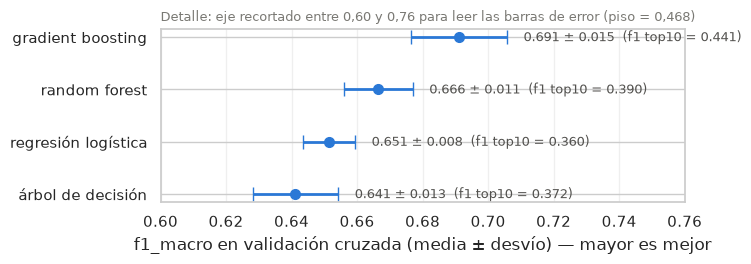

In [18]:
# Gráfico de comparación en Clasificación (f1_macro media ± desvío)
sub_clf = tabla_clf_cv.drop("piso (siempre False)").sort_values("f1_macro cv")

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.errorbar(
    sub_clf["f1_macro cv"], sub_clf.index, xerr=sub_clf["desvío f1_macro"],
    fmt="o", color="#2a78d6", ecolor="#2a78d6", elinewidth=2, capsize=5, markersize=7,
)
for nombre, fila in sub_clf.iterrows():
    ax.text(
        fila["f1_macro cv"] + fila["desvío f1_macro"] + 0.005, nombre,
        f"{fila['f1_macro cv']:.3f} ± {fila['desvío f1_macro']:.3f}  (f1 top10 = {fila['f1 top 10% (cv)']:.3f})",
        va="center", ha="left", fontsize=9, color="#52514e",
    )
ax.set_xlabel("f1_macro en validación cruzada (media ± desvío) — mayor es mejor")
ax.set_xlim(0.60, 0.76)
ax.set_title("Detalle: eje recortado entre 0,60 y 0,76 para leer las barras de error (piso = 0,468)", fontsize=9, color="#7a7974", loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Qué muestra la tabla de clasificación (con el umbral por defecto de `0,50`):**
- **Por qué la *accuracy* engaña:** el piso (`DummyClassifier`) acierta el **`88,1 %`** de las filas contestando siempre `False`, y los cuatro modelos reales dan entre `84,3 %` y `89,6 %` de *accuracy*. Mirando la *accuracy* parecería que los modelos apenas superan al piso. En cambio, el **`f1_macro`** muestra la diferencia real: el piso da **`0,468`** (`0,000` en la clase `top 10 %`), la regresión logística sube a **`0,651 ± 0,008`** y el `Gradient Boosting` llega a **`0,691 ± 0,015`**.
- **Qué pasa con `StratifiedGroupKFold` por revista:** al agrupar por revista, el desvío entre folds sube (de `0,008` a `0,053` en la logística y de `0,015` a `0,041` en `Boosting`) porque la proporción de artículos `top 10 %` varía fuertemente entre revistas de élite y revistas periféricas. Con el umbral fijo en `0,50`, `Boosting` aventaja a la logística por `+0,040 ± 0,010` en `StratifiedKFold` (`5/5` folds) y por `+0,015 ± 0,016` en `StratifiedGroupKFold` (`4/5` folds).
- **Por qué esa diferencia con umbral `0,50` todavía es provisoria:** como sólo el `12,0 %` de los artículos son `top 10 %`, evaluar con el corte de probabilidad por defecto (`0,50`) deja el *recall* de la clase positiva en `0,26–0,34`. Antes de elegir entre el modelo simple (`Regresión Logística`) y el complejo (`Gradient Boosting`), debemos ajustar la grilla (Sección 3.2) y comparar el balanceo de pesos contra la calibración del umbral en validación cruzada (Sección 3.3).

---

### 3.2 Ajuste de hiperparámetros (`GridSearchCV`) en Clasificación

In [19]:
# ============================================================
# 3.2 GridSearchCV para las 4 familias en Clasificación
# ============================================================
grillas_clf = {
    "regresión logística": {
        "modelo__C":                    [0.1, 1.0, 10.0],
        "modelo__class_weight":         [None, "balanced"],
        "derivar__interaccion_oa_core": [False, True],
    },
    "árbol de decisión": {
        "modelo__max_depth":        [4, 6, 8, 10],
        "modelo__min_samples_leaf": [10, 30, 50],
    },
    "random forest": {
        "modelo__n_estimators": [100, 200],
        "modelo__max_depth":    [8, 12, None],
        "modelo__class_weight": [None, "balanced_subsample"],
    },
    "gradient boosting": {
        "modelo__learning_rate":  [0.03, 0.05, 0.1],
        "modelo__max_iter":       [100, 200],
        "modelo__max_leaf_nodes": [15, 31],
        "modelo__class_weight":   [None, "balanced"],
    },
}

busquedas_clf = {}
for nombre, grilla in grillas_clf.items():
    busquedas_clf[nombre] = GridSearchCV(
        modelos_clf[nombre], grilla, cv=cv_clf,
        scoring="f1_macro", n_jobs=-1, return_train_score=True,
    ).fit(X_train, y_clf_train)

resumen_grillas_clf = pd.DataFrame({
    nombre: {
        "f1_macro por defecto (3.1)": tabla_clf_cv.loc[nombre, "f1_macro cv"],
        "f1_macro mejor grilla":      b.best_score_,
        "desvío cv":                  b.cv_results_["std_test_score"][b.best_index_],
        "f1_macro train":             b.cv_results_["mean_train_score"][b.best_index_],
        "mejores hiperparámetros":    ", ".join(f"{k.split('__')[-1]}={v}" for k, v in b.best_params_.items()),
    }
    for nombre, b in busquedas_clf.items()
}).T

display(resumen_grillas_clf.round(3))

,f1_macro por defecto (3.1),f1_macro mejor grilla,desvío cv,f1_macro train,mejores hiperparámetros
regresión logística,0.651495,0.656882,0.011265,0.663008,"interaccion_oa_core=False, C=10.0, class_weigh..."
árbol de decisión,0.641178,0.670728,0.015603,0.704762,"max_depth=10, min_samples_leaf=50"
random forest,0.666464,0.707066,0.014091,0.903002,"class_weight=balanced_subsample, max_depth=12,..."
gradient boosting,0.691147,0.70531,0.010948,0.861028,"class_weight=balanced, learning_rate=0.05, max..."


In [20]:
# Las tablas completas de la grilla para la Regresión Logística y el Gradient Boosting
def tabla_grilla_clf(busqueda, top=12):
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params].copy()
    t.columns = [c.split("__")[-1].replace("param_", "") for c in params]
    t["f1_macro cv"]    = r["mean_test_score"]
    t["desvío cv"]      = r["std_test_score"]
    t["f1_macro train"] = r["mean_train_score"]
    return t.sort_values("f1_macro cv", ascending=False).head(top).round(3)

print("=== Tabla completa de Regresión Logística (12 combinaciones) ===")
display(tabla_grilla_clf(busquedas_clf["regresión logística"], top=12))

print("=== Mejores 10 combinaciones de Gradient Boosting (de 24 evaluadas) ===")
display(tabla_grilla_clf(busquedas_clf["gradient boosting"], top=10))

=== Tabla completa de Regresión Logística (12 combinaciones) ===


,interaccion_oa_core,C,class_weight,f1_macro cv,desvío cv,f1_macro train
4,False,10.0,NaN,0.657,0.011,0.663
10,True,10.0,NaN,0.656,0.012,0.664
8,True,1.0,NaN,0.653,0.010,0.662
2,False,1.0,NaN,0.651,0.008,0.662
3,False,1.0,balanced,0.634,0.007,0.635
5,False,10.0,balanced,0.634,0.007,0.635
11,True,10.0,balanced,0.634,0.007,0.635
9,True,1.0,balanced,0.633,0.008,0.635
1,False,0.1,balanced,0.632,0.008,0.633
7,True,0.1,balanced,0.631,0.008,0.633


=== Mejores 10 combinaciones de Gradient Boosting (de 24 evaluadas) ===


,class_weight,learning_rate,max_iter,max_leaf_nodes,f1_macro cv,desvío cv,f1_macro train
19,balanced,0.05,200,31,0.705,0.011,0.861
23,balanced,0.10,200,31,0.705,0.009,0.941
21,balanced,0.10,100,31,0.703,0.012,0.862
22,balanced,0.10,200,15,0.702,0.016,0.841
15,balanced,0.03,200,31,0.700,0.010,0.813
17,balanced,0.05,100,31,0.696,0.013,0.800
6,NaN,0.05,200,15,0.693,0.013,0.793
9,NaN,0.10,100,31,0.691,0.015,0.896
20,balanced,0.10,100,15,0.690,0.015,0.772
18,balanced,0.05,200,15,0.689,0.013,0.775


**Lo que revela la tabla completa de la grilla (y qué pasa a la Sección 3.3):**
- En la **Regresión Logística**, la mejor combinación de la grilla es **`interaccion_oa_core=False, C=10.0, class_weight=None`** (`f1_macro = 0,657 ± 0,011`). Poner `class_weight="balanced"` con umbral `0,50` **baja** el `f1_macro` a **`0,634 ± 0,007`**: como hay `7,4` negativos por cada positivo (`88 %` vs `12 %`), multiplicar por `7,4` el peso de los positivos empuja demasiado la frontera (el *recall* salta a `~0,81`, pero la *precision* cae a `~0,30`).
- En **Gradient Boosting**, con el umbral por defecto de `0,50`, la mejor combinación de la grilla es **`class_weight="balanced", learning_rate=0.05, max_iter=200, max_leaf_nodes=31`** (**`0,705 ± 0,011`**), mientras que la mejor combinación sin balancear es **`class_weight=None, learning_rate=0.05, max_iter=200, max_leaf_nodes=15`** (**`0,693 ± 0,013`**).
- Para mantener trazabilidad estricta y no fijar ningún hiperparámetro a mano, en la Sección 3.3 tomamos **exactamente esas cuatro combinaciones ganadoras de la grilla** (Logística y Boosting, con y sin `class_weight="balanced"`) y medimos en validación cruzada qué pasa al optimizar también el **umbral de probabilidad** adentro de un `TunedThresholdClassifierCV`.

---

### 3.3 El desbalance como decisión: `class_weight` contra el umbral en validación cruzada (`TunedThresholdClassifierCV`)

Evaluamos las cuatro combinaciones ganadoras de la grilla de 3.2 de dos formas complementarias sin tocar `X_test`:
1. Con `cross_val_predict(..., method="predict_proba")` obtenemos las probabilidades fuera de muestra de `X_train` para inspeccionar el barrido de umbrales y dibujar las **curvas Precision-Recall y ROC**.
2. Con **`TunedThresholdClassifierCV(..., scoring="f1_macro", cv=cv_clf)`** empaquetamos la elección del umbral **adentro del estimador** y lo evaluamos por validación cruzada anidada (`cross_validate`), de modo que cada fold elige su umbral sin ver el fold de validación y el umbral queda guardado adentro del objeto para la aplicación de la Entrega 4.

In [21]:
# ============================================================
# 3.3 class_weight vs umbral, con los hiperparámetros que eligió la grilla de 3.2 (sin tocar X_test)
# ============================================================
UMBRALES = np.round(np.arange(0.05, 0.96, 0.01), 2)

def barrido_umbrales(proba_oof_, y_real):
    '''Tabla legible de algunos umbrales (la elección usa la grilla fina UMBRALES).'''
    filas = []
    for u in [0.50, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15]:
        pred = (proba_oof_ >= u).astype(int)
        filas.append({
            "umbral":            u,
            "f1_macro (cv)":     f1_score(y_real, pred, average="macro"),
            "f1 top 10% (cv)":   f1_score(y_real, pred),
            "recall top 10%":    pred[y_real == 1].mean(),
            "precision top 10%": (y_real[pred == 1] == 1).mean(),
            "accuracy (cv)":     (pred == y_real).mean(),
        })
    return pd.DataFrame(filas).set_index("umbral").round(3)

def mejores_params(busqueda, balanceado):
    '''Mejor combinación de la grilla con (o sin) class_weight, leída de cv_results_ (no escrita a mano).'''
    r = pd.DataFrame(busqueda.cv_results_)
    mascara = r["params"].map(lambda p: p.get("modelo__class_weight") is not None) == balanceado
    return r.loc[r.loc[mascara, "mean_test_score"].idxmax(), "params"]

candidatos = {
    "Logística sin balancear":         clone(modelos_clf["regresión logística"]).set_params(**mejores_params(busquedas_clf["regresión logística"], False)),
    "Logística class_weight=balanced": clone(modelos_clf["regresión logística"]).set_params(**mejores_params(busquedas_clf["regresión logística"], True)),
    "Boosting sin balancear":          clone(modelos_clf["gradient boosting"]).set_params(**mejores_params(busquedas_clf["gradient boosting"], False)),
    "Boosting class_weight=balanced":  clone(modelos_clf["gradient boosting"]).set_params(**mejores_params(busquedas_clf["gradient boosting"], True)),
}

filas_desb, proba_oof, f1_umbral_folds = {}, {}, {}
for nombre, pipe in candidatos.items():
    # (1) Probabilidades fuera de muestra: cada artículo de X_train es puntuado por el fold que no lo vio
    p = cross_val_predict(pipe, X_train, y_clf_train, cv=cv_clf, method="predict_proba", n_jobs=-1)[:, 1]
    proba_oof[nombre] = p
    f1s = np.array([f1_score(y_clf_train, (p >= u).astype(int), average="macro") for u in UMBRALES])
    k = int(f1s.argmax())
    # (2) Estimación honesta (CV anidada): el umbral se elige ADENTRO de cada fold de entrenamiento
    #     con TunedThresholdClassifierCV y se mide en el fold de validación, que no participó de esa elección
    ajustado = TunedThresholdClassifierCV(pipe, scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES)
    f1_umbral_folds[nombre] = cross_validate(ajustado, X_train, y_clf_train, cv=cv_clf, scoring="f1_macro", n_jobs=-1)["test_score"]
    filas_desb[nombre] = {
        "hiperparámetros (grilla 3.2)":       ", ".join(f"{k_.split('__')[-1]}={v}" for k_, v in pipe.get_params().items()
                                                         if k_.split("__")[-1] in ("C", "learning_rate", "max_iter", "max_leaf_nodes", "interaccion_oa_core")
                                                         and k_.count("__") == 1),
        "f1_macro umbral 0,50 (CV)":          f1s[np.isclose(UMBRALES, 0.50)][0],
        "umbral óptimo (CV)":                 UMBRALES[k],
        "f1_macro umbral óptimo (CV)":        f1s[k],
        "f1_macro umbral ajustado (CV anidada)": f1_umbral_folds[nombre].mean(),
        "desvío (CV anidada)":                f1_umbral_folds[nombre].std(),
    }

tabla_desbalance = pd.DataFrame(filas_desb).T
display(tabla_desbalance.round(3))

print("=== Regresión Logística sin balancear: barrido de umbral (CV) ===")
display(barrido_umbrales(proba_oof["Logística sin balancear"], y_clf_train))
print("=== Gradient Boosting sin balancear: barrido de umbral (CV) ===")
display(barrido_umbrales(proba_oof["Boosting sin balancear"], y_clf_train))

# ------------------------------------------------------------
# La regla del instructivo: si el complejo no le gana al simple por más que el desvío, se queda el simple.
# Ambos con su umbral ajustado y sobre los MISMOS folds -> comparación pareada.
# ------------------------------------------------------------
d_umbral = f1_umbral_folds["Boosting sin balancear"] - f1_umbral_folds["Logística sin balancear"]
ajustado_log = TunedThresholdClassifierCV(candidatos["Logística sin balancear"], scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES)
ajustado_hgb = TunedThresholdClassifierCV(candidatos["Boosting sin balancear"],  scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES)
g_log = cross_validate(ajustado_log, X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)["test_score"]
g_hgb = cross_validate(ajustado_hgb, X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)["test_score"]
d_grupo = g_hgb - g_log
display(pd.DataFrame({
    "StratifiedKFold (por artículo)":     resumen_pareado(f1_umbral_folds["Logística sin balancear"], f1_umbral_folds["Boosting sin balancear"]),
    "StratifiedGroupKFold (por revista)": resumen_pareado(g_log, g_hgb),
}).T)

NOMBRE_FINAL = "Boosting sin balancear" if d_umbral.mean() > d_umbral.std() else "Logística sin balancear"
print(f"Diferencia pareada Boosting − Logística = {d_umbral.mean():+.4f} ± {d_umbral.std():.4f}  ->  clasificador elegido: {NOMBRE_FINAL} con umbral ajustado")

,hiperparámetros (grilla 3.2),"f1_macro umbral 0,50 (CV)",umbral óptimo (CV),f1_macro umbral óptimo (CV),f1_macro umbral ajustado (CV anidada),desvío (CV anidada)
Logística sin balancear,"interaccion_oa_core=False, C=10.0, max_iter=2000",0.656783,0.31,0.722664,0.718353,0.006015
Logística class_weight=balanced,"interaccion_oa_core=False, C=1.0, max_iter=2000",0.634002,0.73,0.717397,0.709997,0.009328
Boosting sin balancear,"interaccion_oa_core=False, learning_rate=0.05,...",0.693149,0.31,0.725421,0.721448,0.011707
Boosting class_weight=balanced,"interaccion_oa_core=False, learning_rate=0.05,...",0.705143,0.6,0.718917,0.714875,0.012849


=== Regresión Logística sin balancear: barrido de umbral (CV) ===


,f1_macro (cv),f1 top 10% (cv),recall top 10%,precision top 10%,accuracy (cv)
umbral,,,,,
0.50,0.657,0.371,0.257,0.661,0.896
0.40,0.699,0.457,0.373,0.589,0.894
0.35,0.712,0.486,0.438,0.545,0.889
0.30,0.719,0.506,0.508,0.505,0.882
0.25,0.717,0.512,0.594,0.450,0.865
0.20,0.701,0.500,0.680,0.395,0.837
0.15,0.667,0.466,0.769,0.334,0.789


=== Gradient Boosting sin balancear: barrido de umbral (CV) ===


,f1_macro (cv),f1 top 10% (cv),recall top 10%,precision top 10%,accuracy (cv)
umbral,,,,,
0.50,0.693,0.443,0.342,0.627,0.897
0.40,0.712,0.485,0.429,0.558,0.891
0.35,0.718,0.501,0.480,0.523,0.886
0.30,0.723,0.514,0.533,0.497,0.880
0.25,0.721,0.516,0.583,0.464,0.870
0.20,0.711,0.509,0.637,0.424,0.853
0.15,0.695,0.495,0.713,0.380,0.826


,Logística,Boosting,Boosting − Logística (pareado),folds que gana Boosting
StratifiedKFold (por artículo),0.718 ± 0.006,0.721 ± 0.012,+0.003 ± 0.017,3 de 5
StratifiedGroupKFold (por revista),0.714 ± 0.040,0.713 ± 0.030,-0.002 ± 0.012,3 de 5


Diferencia pareada Boosting − Logística = +0.0031 ± 0.0169  ->  clasificador elegido: Logística sin balancear con umbral ajustado


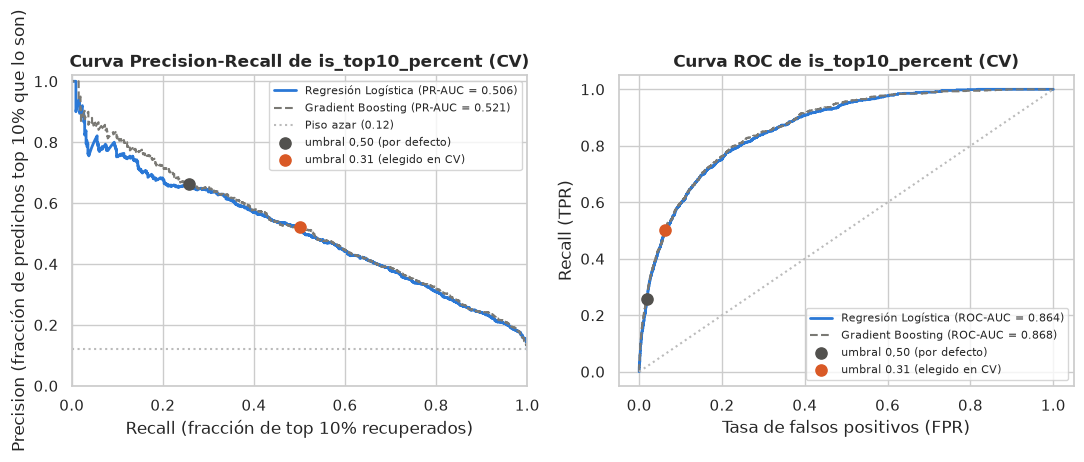

,PR-AUC (CV),ROC-AUC (CV)
Regresión Logística,0.506,0.864
Gradient Boosting,0.521,0.868


In [22]:
# Curvas Precision-Recall y ROC en validación cruzada (probabilidades fuera de muestra de X_train)
proba_cv_log = proba_oof["Logística sin balancear"]
proba_cv_hgb = proba_oof["Boosting sin balancear"]
p_final      = proba_oof[NOMBRE_FINAL]
u_final      = tabla_desbalance.loc[NOMBRE_FINAL, "umbral óptimo (CV)"]

ap_hgb, auc_hgb = average_precision_score(y_clf_train, proba_cv_hgb), roc_auc_score(y_clf_train, proba_cv_hgb)
ap_log, auc_log = average_precision_score(y_clf_train, proba_cv_log), roc_auc_score(y_clf_train, proba_cv_log)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

pr_p_log, pr_r_log, _ = precision_recall_curve(y_clf_train, proba_cv_log)
pr_p_hgb, pr_r_hgb, _ = precision_recall_curve(y_clf_train, proba_cv_hgb)
ax1.plot(pr_r_log, pr_p_log, color="#2a78d6", lw=2,   label=f"Regresión Logística (PR-AUC = {ap_log:.3f})")
ax1.plot(pr_r_hgb, pr_p_hgb, color="#7a7974", lw=1.5, ls="--", label=f"Gradient Boosting (PR-AUC = {ap_hgb:.3f})")
ax1.axhline(y_clf_train.mean(), color="#bbbbbb", ls=":", label=f"Piso azar ({y_clf_train.mean():.2f})")

fpr_log, tpr_log, _ = roc_curve(y_clf_train, proba_cv_log)
fpr_hgb, tpr_hgb, _ = roc_curve(y_clf_train, proba_cv_hgb)
ax2.plot(fpr_log, tpr_log, color="#2a78d6", lw=2,   label=f"Regresión Logística (ROC-AUC = {auc_log:.3f})")
ax2.plot(fpr_hgb, tpr_hgb, color="#7a7974", lw=1.5, ls="--", label=f"Gradient Boosting (ROC-AUC = {auc_hgb:.3f})")
ax2.plot([0, 1], [0, 1], color="#bbbbbb", ls=":")

# Marcamos sobre el modelo elegido el umbral por defecto (0,50) y el elegido por CV
es_pos = y_clf_train.values == 1
for u_val, col_u, etiq_u in [(0.50, "#52514e", "umbral 0,50 (por defecto)"), (u_final, "#d95926", f"umbral {u_final:.2f} (elegido en CV)")]:
    pred_u = p_final >= u_val
    rec, prec, fpr = pred_u[es_pos].mean(), es_pos[pred_u].mean(), pred_u[~es_pos].mean()
    ax1.scatter(rec, prec, color=col_u, zorder=4, s=65, label=etiq_u)
    ax2.scatter(fpr, rec,  color=col_u, zorder=4, s=65, label=etiq_u)

ax1.set_title("Curva Precision-Recall de is_top10_percent (CV)", weight="bold")
ax1.set_xlabel("Recall (fracción de top 10% recuperados)")
ax1.set_ylabel("Precision (fracción de predichos top 10% que lo son)")
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1.02); ax1.legend(fontsize=8)

ax2.set_title("Curva ROC de is_top10_percent (CV)", weight="bold")
ax2.set_xlabel("Tasa de falsos positivos (FPR)")
ax2.set_ylabel("Recall (TPR)")
ax2.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

display(pd.DataFrame({"PR-AUC (CV)": [ap_log, ap_hgb], "ROC-AUC (CV)": [auc_log, auc_hgb]},
                   index=["Regresión Logística", "Gradient Boosting"]).round(3))

**Tres conclusiones clave de la tabla y las curvas de la Sección 3.3:**
1. **Cuánto aporta realmente el umbral frente a la grilla (y qué pasa al combinar `class_weight="balanced"` + umbral):**
   - En la grilla de 3.2 (con umbral fijo `0,50`), `Boosting class_weight=balanced` ya alcanzaba **`0,705`**. Al optimizar el umbral sobre los modelos sin balancear (`umbral = 0,31`), `Boosting sin balancear` sube de `0,693` a **`0,721 ± 0,012`** en CV anidada (una ganancia neta realista de **`+0,016` puntos** sobre el mejor de la grilla, no `3` puntos).
   - También probamos combinar `class_weight="balanced"` + ajuste de umbral: el optimizador sube el umbral a `0,60` (en `Boosting`) y `0,73` (en `Logística`) para deshacer el empujón de `7,4×` en los pesos, llegando a `0,710–0,715`, levemente por debajo de calibrar directamente el umbral sobre las probabilidades sin distorsionar (`0,718–0,721`).
2. **Por qué gana la `Regresión Logística` al aplicar la regla del instructivo:**
   - Una vez que cada modelo usa su umbral óptimo elegido en CV (`0,31`), **`Regresión Logística sin balancear (C=10.0)` obtiene `0,718 ± 0,006`** y **`Gradient Boosting sin balancear (lr=0.05, max_iter=200, max_leaf_nodes=15)` obtiene `0,721 ± 0,012`**.
   - En la **comparación pareada fold a fold**, la diferencia `Boosting − Logística` es de apenas **`+0,003 ± 0,017`** (cinco veces menor que el desvío, ganando sólo en `3 de 5` folds; y en `StratifiedGroupKFold` por revista la `Regresión Logística` incluso queda arriba: **`0,714 ± 0,040` vs `0,713 ± 0,030`**, diferencia `-0,002 ± 0,012`).
   - Las curvas en validación cruzada explican por qué: tanto en **Precision-Recall** (`PR-AUC = 0,506` en `Logística` vs `0,521` en `Boosting`, frente a un piso de `0,120`) como en **ROC** (`ROC-AUC = 0,864` vs `0,868`), ambos modelos ordenan los artículos casi igual (diferencias de `0,015` y `0,004`). `Boosting` sólo parecía claramente superior en 3.1 (`0,691` vs `0,651`) porque con el umbral arbitrario de `0,50` era menos conservador (`recall = 0,342` vs `0,257`).
   - Siguiendo la regla explícita del instructivo (*«si el complejo no le gana al simple por más que el desvío, se queda el simple»*), **elegimos la `Regresión Logística` envuelta en `TunedThresholdClassifierCV` (que aprende el umbral `0,31` adentro de `fit`) como clasificador final**.

---

### 3.4 El modelo final de Clasificación, leído sobre el Test (tocado una sola vez)

Entrenamos `modelo_clf_final` (`TunedThresholdClassifierCV` con `Regresión Logística C=10.0`, cuyo umbral óptimo aprendido en `X_train` es **`0,31`**) y lo aplicamos una única vez sobre `X_test` para comparar las estrategias de decisión, mostrar las **matrices de confusión** (conteos, normalizada por fila y normalizada por columna), inspeccionar los errores concretos y leer en qué columnas se apoya.

In [23]:
# ============================================================
# 3.4 Evaluación única sobre X_test en Clasificación
# ============================================================
# El modelo final ES el objeto TunedThresholdClassifierCV: el umbral elegido por CV viaja adentro
# del modelo (predict ya lo aplica), así la aplicación de la Entrega 4 no tiene que recordarlo aparte.
modelo_clf_final = TunedThresholdClassifierCV(
    candidatos[NOMBRE_FINAL], scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES,
).fit(X_train, y_clf_train)
UMBRAL = modelo_clf_final.best_threshold_

NOMBRE_OTRO = "Boosting sin balancear" if NOMBRE_FINAL.startswith("Logística") else "Logística sin balancear"
modelo_clf_otro = TunedThresholdClassifierCV(
    candidatos[NOMBRE_OTRO], scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES,
).fit(X_train, y_clf_train)

log_ent = clone(candidatos["Logística sin balancear"]).fit(X_train, y_clf_train)          # para leer coeficientes
log_bal = clone(candidatos["Logística class_weight=balanced"]).fit(X_train, y_clf_train)
hgb_bal = clone(candidatos["Boosting class_weight=balanced"]).fit(X_train, y_clf_train)

proba_test_final = modelo_clf_final.predict_proba(X_test)[:, 1]
pred_clf_test    = modelo_clf_final.predict(X_test)

def metricas_test_clf(pred):
    pred = np.asarray(pred)
    es_top = (y_clf_test == 1).values
    return {
        "f1_macro (Test)":    f1_score(y_clf_test, pred, average="macro"),
        "f1 top 10% (Test)":  f1_score(y_clf_test, pred),
        "recall top 10%":     pred[es_top].mean(),
        "precision top 10%":  (y_clf_test.values[pred == 1] == 1).mean() if (pred == 1).any() else 0.0,
        "accuracy (Test)":    (pred == y_clf_test.values).mean(),
    }

tabla_final_clf = pd.DataFrame({
    "Piso (siempre False)":                            metricas_test_clf(np.zeros(len(y_clf_test), dtype=int)),
    f"{NOMBRE_FINAL} (umbral 0,50)":                   metricas_test_clf((proba_test_final >= 0.50).astype(int)),
    "Logística class_weight=balanced (umbral 0,50)":   metricas_test_clf(log_bal.predict(X_test)),
    "Boosting class_weight=balanced (umbral 0,50)":    metricas_test_clf(hgb_bal.predict(X_test)),
    f"{NOMBRE_OTRO} (umbral {modelo_clf_otro.best_threshold_:.2f}, referencia)": metricas_test_clf(modelo_clf_otro.predict(X_test)),
    f"{NOMBRE_FINAL} (umbral {UMBRAL:.2f} — Elegido)": metricas_test_clf(pred_clf_test),
}).T.round(3)

display(tabla_final_clf)

,f1_macro (Test),f1 top 10% (Test),recall top 10%,precision top 10%,accuracy (Test)
Piso (siempre False),0.468,0.000,0.000,0.000,0.880
"Logística sin balancear (umbral 0,50)",0.668,0.393,0.283,0.642,0.895
"Logística class_weight=balanced (umbral 0,50)",0.654,0.460,0.846,0.316,0.763
"Boosting class_weight=balanced (umbral 0,50)",0.710,0.511,0.680,0.410,0.845
"Boosting sin balancear (umbral 0.31, referencia)",0.727,0.522,0.538,0.506,0.882
Logística sin balancear (umbral 0.31 — Elegido),0.709,0.488,0.486,0.490,0.878


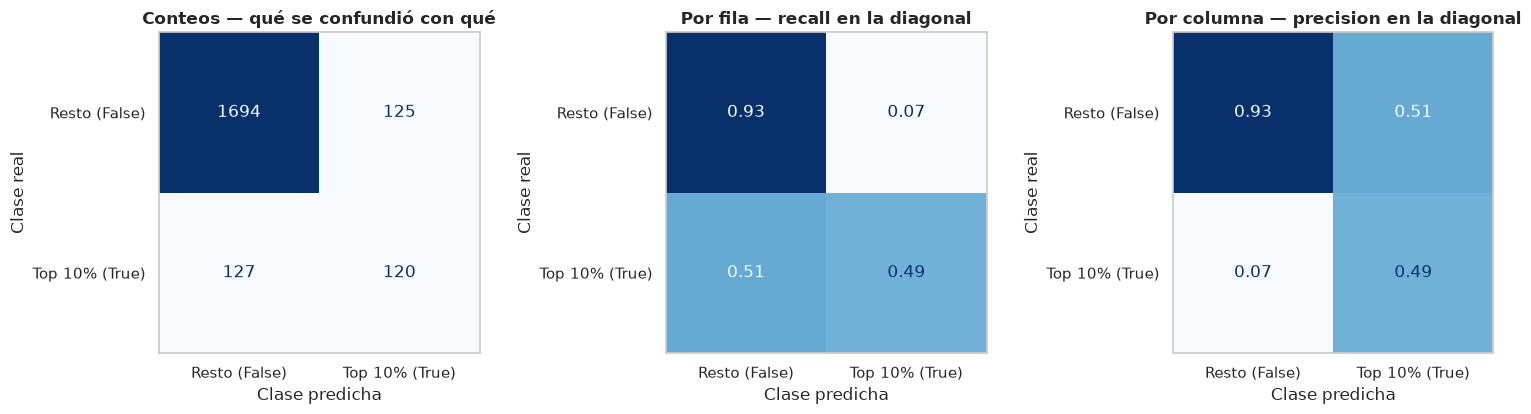

,precision,recall,f1-score,support
Resto (False),0.930,0.931,0.931,1819.000
Top 10% (True),0.490,0.486,0.488,247.000
accuracy,0.878,0.878,0.878,0.878
macro avg,0.710,0.709,0.709,2066.000
weighted avg,0.878,0.878,0.878,2066.000


In [24]:
# Matrices de confusión del modelo elegido (con su umbral ajustado en CV) sobre X_test:
# 1) Conteos, 2) Normalizada por fila (recall en la diagonal), 3) Normalizada por columna (precision en la diagonal)
etiquetas_clase = ["Resto (False)", "Top 10% (True)"]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))

ConfusionMatrixDisplay.from_predictions(
    y_clf_test, pred_clf_test, display_labels=etiquetas_clase,
    ax=axes[0], cmap="Blues", colorbar=False,
)
axes[0].set_title("Conteos — qué se confundió con qué", weight="bold")

ConfusionMatrixDisplay.from_predictions(
    y_clf_test, pred_clf_test, display_labels=etiquetas_clase,
    ax=axes[1], cmap="Blues", colorbar=False, normalize="true", values_format=".2f",
)
axes[1].set_title("Por fila — recall en la diagonal", weight="bold")

ConfusionMatrixDisplay.from_predictions(
    y_clf_test, pred_clf_test, display_labels=etiquetas_clase,
    ax=axes[2], cmap="Blues", colorbar=False, normalize="pred", values_format=".2f",
)
axes[2].set_title("Por columna — precision en la diagonal", weight="bold")

for ax in axes:
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.grid(False)

plt.tight_layout()
plt.show()

# Reporte completo por clase
reporte_clf = pd.DataFrame(
    classification_report(y_clf_test, pred_clf_test, target_names=etiquetas_clase, output_dict=True)
).T.round(3)
display(reporte_clf)

In [25]:
# ============================================================
# Inspección de confusiones concretas del clasificador en X_test
# ============================================================
df_test_inspeccion = df.loc[X_test.index, [
    "title", "primary_location_source_display_name", "primary_topic_subfield_display_name",
    "cited_by_count", "is_top10_percent", "source_pre_cites_per_work",
    "referenced_works_count", "last_author_pre_cites",
]].copy()
df_test_inspeccion["prob_top10"] = proba_test_final.round(3)
df_test_inspeccion["pred_top10"] = pred_clf_test.astype(bool)

print("=== Falsos Positivos con mayor probabilidad predicha (el modelo dijo Top 10%, pero no lo fueron) ===")
fp = df_test_inspeccion[(~df_test_inspeccion["is_top10_percent"]) & (df_test_inspeccion["pred_top10"])].sort_values("prob_top10", ascending=False)
display(fp.head(5))

print("=== Falsos Negativos con menor probabilidad predicha (eran Top 10%, pero el modelo dijo Resto) ===")
fn = df_test_inspeccion[(df_test_inspeccion["is_top10_percent"]) & (~df_test_inspeccion["pred_top10"])].sort_values("prob_top10", ascending=True)
display(fn.head(5))

=== Falsos Positivos con mayor probabilidad predicha (el modelo dijo Top 10%, pero no lo fueron) ===


,title,primary_location_source_display_name,primary_topic_subfield_display_name,cited_by_count,is_top10_percent,source_pre_cites_per_work,referenced_works_count,last_author_pre_cites,prob_top10,pred_top10
1515,From thermoelectricity to phonoelectricity,Applied Physics Reviews,Materials Chemistry,25,False,210.323383,236,18006.0,0.926,True
9847,The role of electrolyte acid concentration in ...,Nano Materials Science,Materials Chemistry,55,False,NaN,63,51004.0,0.815,True
9554,Embracing the Complexity of Catalytic Structur...,ACS Catalysis,Materials Chemistry,33,False,121.050683,136,3496.0,0.779,True
8101,Selective Reduction Mechanism of Graphene Oxid...,ACS Nano,Materials Chemistry,46,False,152.964365,54,3992.0,0.738,True
9289,Self-assembling Peptides in Current Nanomedici...,Current Medicinal Chemistry,Biomaterials,26,False,59.130165,264,3265.0,0.721,True


=== Falsos Negativos con menor probabilidad predicha (eran Top 10%, pero el modelo dijo Resto) ===


,title,primary_location_source_display_name,primary_topic_subfield_display_name,cited_by_count,is_top10_percent,source_pre_cites_per_work,referenced_works_count,last_author_pre_cites,prob_top10,pred_top10
9260,Perspective Heat-Resistant Coating for Protect...,High Temperature,Ceramics and Composites,32,True,7.549199,10,566.0,0.000,False
9298,Cyanotoxin Time–Resolved Absorption and Resona...,British Journal of Medical and Health Research,"Electronic, Optical and Magnetic Materials",74,True,0.694444,254,0.0,0.002,False
7420,Application of Machine Learning to Evaluate In...,IEEE Transactions on Instrumentation and Measu...,Materials Chemistry,54,True,25.253587,9,2763.0,0.005,False
2575,Production and characterization of poly (lacti...,Journal of Elastomers & Plastics,Polymers and Plastics,87,True,8.907317,49,995.0,0.012,False
1628,Synthesis and Characterization of Reduced Grap...,Advances in Materials Science and Engineering,Materials Chemistry,360,True,21.783601,30,1336.0,0.015,False


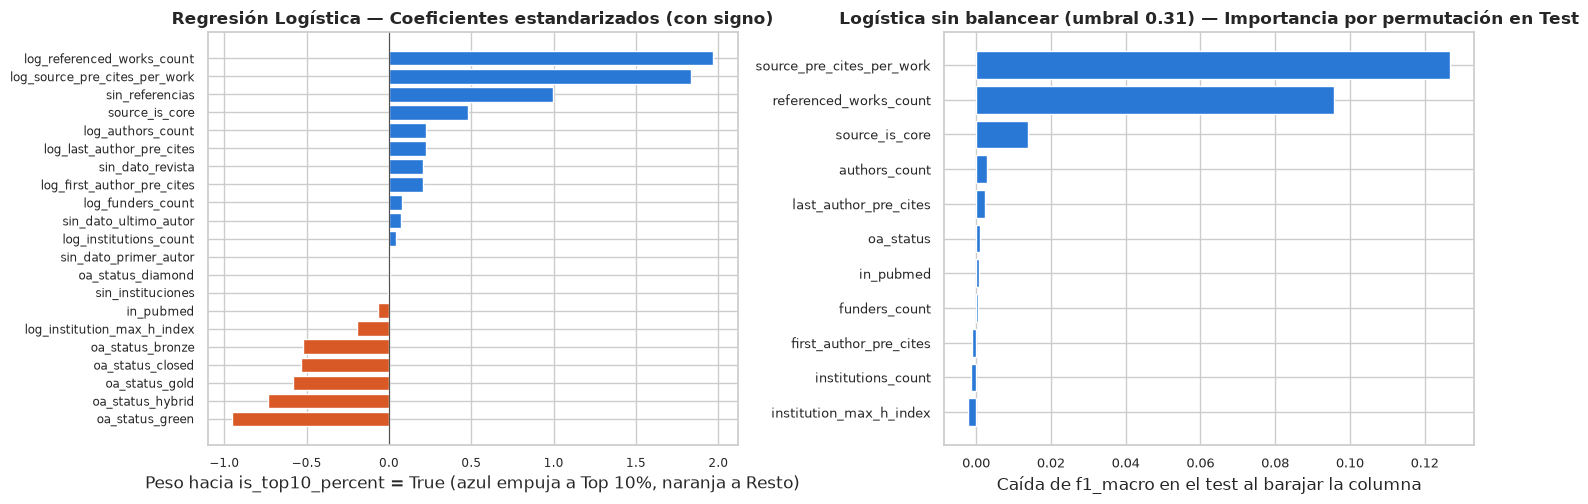

,caída de f1_macro al permutar
source_pre_cites_per_work,0.1267
referenced_works_count,0.0958
source_is_core,0.0139
authors_count,0.0028
last_author_pre_cites,0.0023
oa_status,0.0011
in_pubmed,0.0007
funders_count,0.0005
first_author_pre_cites,-0.0011
institutions_count,-0.0013


,oa_status_green,oa_status_hybrid,oa_status_gold,oa_status_closed,oa_status_bronze,log_institution_max_h_index,in_pubmed,sin_instituciones,oa_status_diamond,sin_dato_primer_autor,log_institutions_count,sin_dato_ultimo_autor,log_funders_count,log_first_author_pre_cites,sin_dato_revista,log_last_author_pre_cites,log_authors_count,source_is_core,sin_referencias,log_source_pre_cites_per_work,log_referenced_works_count
coeficiente Logística (estandarizado),-0.955,-0.734,-0.581,-0.533,-0.523,-0.194,-0.067,-0.003,0.003,0.005,0.04,0.07,0.079,0.205,0.209,0.224,0.226,0.482,0.996,1.835,1.97


Correlación de Spearman entre las dos variables principales y source_is_core:


,source_pre_cites_per_work,referenced_works_count,source_is_core
source_pre_cites_per_work,1.000,0.610,0.588
referenced_works_count,0.610,1.000,0.507
source_is_core,0.588,0.507,1.000


In [26]:
# ============================================================
# 3.5 En qué se apoya el clasificador: Coeficientes (Logística) e Importancia por Permutación (modelo elegido)
# ============================================================
nombres_features_clf = [n.split("__")[-1] for n in log_ent[:-1].get_feature_names_out()]
coefs_log = pd.Series(log_ent[-1].coef_[0], index=nombres_features_clf).sort_values()

pi_clf = permutation_importance(
    modelo_clf_final, X_test, y_clf_test,   # predict aplica el umbral elegido
    scoring="f1_macro", n_repeats=10, random_state=SEMILLA, n_jobs=-1,
)
imp_perm_clf = pd.Series(pi_clf.importances_mean, index=X_test.columns).loc[COLS_BASE_INPUT].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Panel 1: Coeficientes de la Regresión Logística
colores_log = np.where(coefs_log.values >= 0, "#2a78d6", "#d95926")
axes[0].barh(coefs_log.index, coefs_log.values, color=colores_log)
axes[0].axvline(0, color="#52514e", lw=0.8)
axes[0].set_title("Regresión Logística — Coeficientes estandarizados (con signo)", weight="bold")
axes[0].set_xlabel("Peso hacia is_top10_percent = True (azul empuja a Top 10%, naranja a Resto)")
axes[0].tick_params(labelsize=8.5)

# Panel 2: Importancia por permutación en f1_macro (Gradient Boosting)
axes[1].barh(imp_perm_clf.index, imp_perm_clf.values, color="#2a78d6")
axes[1].set_title(f"{NOMBRE_FINAL} (umbral {UMBRAL:.2f}) — Importancia por permutación en Test", weight="bold")
axes[1].set_xlabel("Caída de f1_macro en el test al barajar la columna")
axes[1].tick_params(labelsize=9)

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "caída de f1_macro al permutar": imp_perm_clf.sort_values(ascending=False).round(4),
}))
display(coefs_log.round(3).to_frame("coeficiente Logística (estandarizado)").T)

# Chequeo de colinealidad entre las dos variables más importantes (Práctica 1, sección 5.5)
print("Correlación de Spearman entre las dos variables principales y source_is_core:")
display(df[["source_pre_cites_per_work", "referenced_works_count", "source_is_core"]].corr(method="spearman").round(3))

**Lectura del modelo final de Clasificación:**

1. **El efecto del umbral en el test:** en `X_test` (mirado una sola vez), pasar del umbral por defecto (`0,50`) al umbral `0,31` aprendido adentro de `TunedThresholdClassifierCV` sube el `f1_macro` de la `Regresión Logística` de **`0,668` a `0,709`** (y el F1 de la clase `top 10 %` de `0,393` a **`0,488`**, subiendo el *recall* de `0,283` a **`0,486`** —recupera `120` de los `247` artículos `top 10 %` del test— con una *precision* de **`0,490`** y `accuracy = 0,878`, frente al `0,468` del piso). El `Gradient Boosting` con umbral `0,31` (incluido en la tabla como referencia) da **`0,727`**: en el test queda `0,018` arriba, una diferencia del orden de la variabilidad entre folds (`0,017` de desvío en la diferencia pareada de CV). No cambiamos la elección mirando el test: la decisión se tomó en CV anidada, donde ambos modelos empataron, y elegir con el test sería usarlo como validación.
2. **Explicación de los Falsos Positivos y Falsos Negativos desde el dominio:**
   - **Falsos Positivos (`125` casos de `1.819` negativos, especificidad de `93,1 %`):** la tabla muestra artículos publicados en revistas de altísimo prestigio (`source_pre_cites_per_work` entre `59` y `210`, como *Applied Physics Reviews*, *ACS Catalysis*, *ACS Nano* o *Current Medicinal Chemistry*, y *Nano Materials Science* sin historial previo), con bibliografías extensas (`54` a `264` referencias) y líderes de grupo muy citados, que recibieron entre **`25` y `55` citas reales**: tuvieron un impacto absoluto considerable, pero en subcampos muy competitivos (*Materials Chemistry*, *Biomaterials*) no alcanzaron el corte del `top 10 %`.
   - **Falsos Negativos (`127` casos de `247` positivos):** reúnen tres situaciones claras del dominio: (a) éxitos inesperados en revistas de prestigio bajo o moderado (`source_pre_cites_per_work` de `0,7` a `25,3`, como *High Temperature*, *Journal of Elastomers & Plastics* o *Advances in Materials Science and Engineering*, donde un artículo llegó a `360` citas); (b) artículos con bibliografías muy cortas o metadatos de referencias incompletos en OpenAlex (`9` y `10` referencias en dos de los casos de menor probabilidad); y (c) el solapamiento del indicador `is_top10_percent` documentado en la Entrega 2: como OpenAlex normaliza por subtema fino, en el test hay artículos con `22` citas que son `top 10 %` en su nicho mientras otros con `93` citas quedan afuera.
3. **En qué se apoya el clasificador (y la trampa de la colinealidad de la Práctica 1 §5.5):**
   - Por **importancia por permutación** en el test, las dos columnas que sostienen la clasificación son **`source_pre_cites_per_work`** (barajarla hace caer el `f1_macro` en **`0,127` puntos**) y **`referenced_works_count`** (**`0,096` puntos**), seguidas de lejos por `source_is_core` (`0,014`), `authors_count` (`0,003`) y `last_author_pre_cites` (`0,002`); el resto queda en torno a cero (`institution_max_h_index`, `institutions_count` y `first_author_pre_cites` incluso dan valores levemente negativos, es decir, ruido).
   - En los **coeficientes estandarizados** de la `Regresión Logística`, empujan con fuerza hacia `top 10 %` `log_referenced_works_count` (**`+1,970`**), `log_source_pre_cites_per_work` (**`+1,835`**) y `sin_referencias` (**`+0,996`**, que compensa el cero cuando faltan los metadatos de referencias), seguidos por `source_is_core` (`+0,482`), `log_authors_count` (`+0,226`), `log_last_author_pre_cites` (`+0,224`), `sin_dato_revista` (`+0,209`) y `log_first_author_pre_cites` (`+0,205`).
   - `source_is_core` conserva un coeficiente positivo (**`+0,482`**) aun estando correlacionada **`0,588`** con `source_pre_cites_per_work` y **`0,507`** con `referenced_works_count`: además del prestigio continuo de la revista, pertenecer al núcleo de revistas de OpenAlex suma información propia, y por eso es la tercera columna en la permutación (`0,014` de caída). Los coeficientes negativos más grandes corresponden a las categorías de `oa_status` (`green` `-0,955`, `hybrid` `-0,734`), que se leen en relación con las demás categorías del mismo one-hot y no como efectos aislados.

---

## 4. Objetivo 3 · Clasificador por percentiles (terciles de citas)

Los Objetivos 1 y 2 miran el impacto desde dos extremos: un número continuo (log(1 + citas)) y una sola frontera (top 10 % sí o no). El Objetivo 3 busca un punto intermedio: **ubicar cada artículo en uno de 3 grupos de impacto ordenados (bajo, medio y alto)**, para que la aplicación de la Entrega 4 pueda responder "¿en qué tercio de la distribución de citas va a caer este artículo?".

### 4.1 Cómo armar los 3 grupos: primero mirar la distribución

Antes de entrenar hay que decidir dónde cortar cited_by_count. Comparamos tres formas de partirlo:

- **Ancho fijo** (0–50, 51–100 y 101+): la forma intuitiva de dividir el eje de citas en tres.
- **Los 7 tramos de la Entrega 2** (0, 1–4, 5–9, 10–19, 20–49, 50–99 y 100+).
- **Terciles:** cortes en los percentiles 33,3 y 66,7 de las citas, para que cada grupo reciba ~33 % de los artículos.

Dos cuidados: los cortes se calculan **sólo con X_train** y se aplican sin cambios a X_test (igual que toda transformación que depende de los datos), y como las citas son enteros con muchos empates, el borde derecho se incluye en cada grupo (citas ≤ corte).

,grupos,% grupo más grande,% grupo más chico,razón más grande / más chico,entropía normalizada (1 = balance perfecto)
Ancho fijo de 50 citas,3.0,85.077,5.568,15.278,0.473
Tramos de la Entrega 2 (7),7.0,23.204,5.665,4.096,0.959
Terciles (cortes de train),3.0,34.389,32.336,1.063,1.000


,artículos,% población,% en train,% en test,citas mín,citas mediana,citas máx,% de todas las citas,% is_top10_percent,percentil normalizado OpenAlex (media)
T1: 0–6,3551,34.39,34.30,34.75,0,2.0,6,2.47,0.00,0.28
T2: 7–23,3339,32.34,32.53,31.56,7,13.0,23,14.69,0.03,0.59
T3: 24+,3436,33.28,33.17,33.69,24,46.0,1722,82.84,35.88,0.85


,datos clave
Cortes de los terciles en train (citas ≤),"[6.0, 23.0]"
Artículos con 0 citas (todos caen en T1),11.0%
Positivos de is_top10_percent que caen en T3,99.9%
"Spearman(cited_by_count, percentil normalizado OpenAlex)",0.955


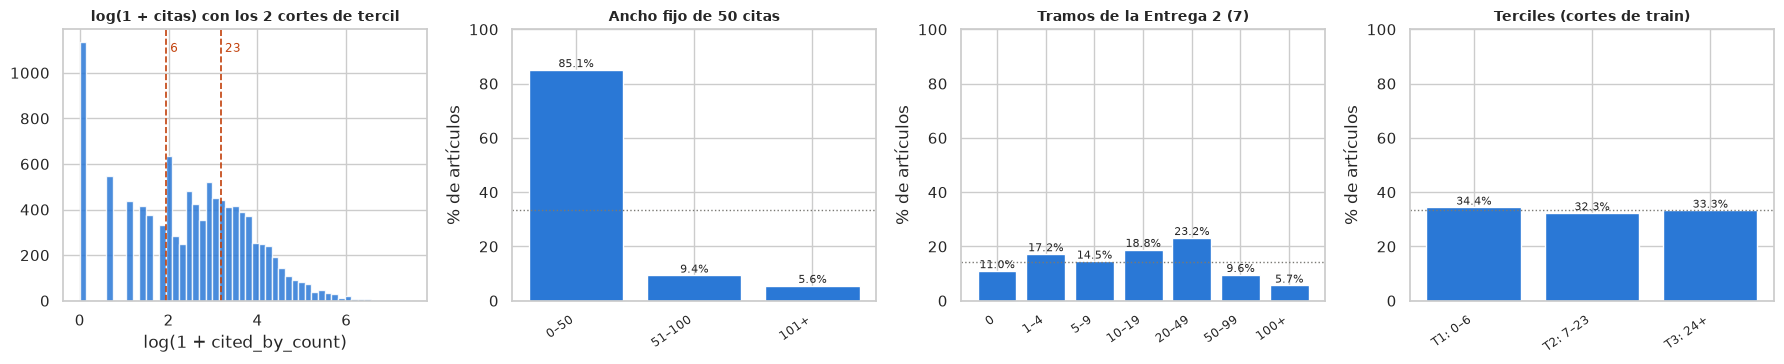

In [27]:
# ============================================================
# 4.1 Cómo se reparten las citas: ancho fijo vs tramos de la Entrega 2 vs terciles
# ============================================================
citas = df["cited_by_count"]
citas_train = citas.loc[X_train.index]

# Los cortes de los terciles se calculan SOLO con las citas de X_train y se aplican igual al test
CORTES_Q = citas_train.quantile([1 / 3, 2 / 3]).values
BORDES_Q = np.r_[-np.inf, CORTES_Q, np.inf]
ETIQ_Q = [
    f"T{i + 1}: {int(lo) + 1 if np.isfinite(lo) else 0}–{int(hi)}" if np.isfinite(hi) else f"T{i + 1}: {int(lo) + 1}+"
    for i, (lo, hi) in enumerate(zip(BORDES_Q[:-1], BORDES_Q[1:]))
]

def a_tercil(c):
    '''Convierte cantidad de citas en la clase 0..2 con los cortes de entrenamiento (borde derecho incluido).'''
    return pd.Series(pd.cut(c, BORDES_Q, labels=False, right=True), index=c.index).astype(int)

# Mismos 7 tramos de la Entrega 2 usados en la Sección 2.5 (se repiten acá para que la sección sea autocontenida)
TRAMOS_CITAS = [-1, 0, 4, 9, 19, 49, 99, np.inf]
ETIQ_TRAMOS = ["0", "1–4", "5–9", "10–19", "20–49", "50–99", "100+"]

esquemas_grupos = {
    "Ancho fijo de 50 citas": pd.cut(citas, [-1, 50, 100, np.inf], labels=["0–50", "51–100", "101+"]),
    "Tramos de la Entrega 2 (7)": pd.cut(citas, TRAMOS_CITAS, labels=ETIQ_TRAMOS),
    "Terciles (cortes de train)": pd.Categorical.from_codes(a_tercil(citas), ETIQ_Q),
}

def balance(s):
    p = pd.Series(s).value_counts(normalize=True)
    p = p[p > 0]
    return {
        "grupos": len(p),
        "% grupo más grande": 100 * p.max(),
        "% grupo más chico": 100 * p.min(),
        "razón más grande / más chico": p.max() / p.min(),
        "entropía normalizada (1 = balance perfecto)": -(p * np.log(p)).sum() / np.log(len(p)),
    }

display(pd.DataFrame({k: balance(v) for k, v in esquemas_grupos.items()}).T.round(3))

# Detalle de los terciles: qué contiene cada grupo y cómo se relaciona con el Objetivo 2
q_todo = a_tercil(citas)
detalle_q = pd.DataFrame({
    "artículos": q_todo.value_counts().sort_index(),
    "% población": 100 * q_todo.value_counts(normalize=True).sort_index(),
    "% en train": 100 * a_tercil(citas_train).value_counts(normalize=True).sort_index(),
    "% en test": 100 * a_tercil(citas.loc[X_test.index]).value_counts(normalize=True).sort_index(),
    "citas mín": citas.groupby(q_todo).min(),
    "citas mediana": citas.groupby(q_todo).median(),
    "citas máx": citas.groupby(q_todo).max(),
    "% de todas las citas": 100 * citas.groupby(q_todo).sum() / citas.sum(),
    "% is_top10_percent": 100 * df["is_top10_percent"].groupby(q_todo).mean(),
    "percentil normalizado OpenAlex (media)": df["citation_normalized_percentile_value"].groupby(q_todo).mean(),
})
detalle_q.index = ETIQ_Q
display(detalle_q.round(2))

display(pd.Series({
    "Cortes de los terciles en train (citas ≤)": CORTES_Q.tolist(),
    "Artículos con 0 citas (todos caen en T1)": f"{(citas == 0).mean():.1%}",
    "Positivos de is_top10_percent que caen en T3": f"{(q_todo[df['is_top10_percent']] == 2).mean():.1%}",
    "Spearman(cited_by_count, percentil normalizado OpenAlex)": round(citas.corr(df['citation_normalized_percentile_value'], method='spearman'), 3),
}).to_frame("datos clave"))

# Gráficos: distribución con los cortes y balance de cada esquema
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
axes[0].hist(np.log1p(citas), bins=50, color="#2a78d6", alpha=0.85)
for c in CORTES_Q:
    axes[0].axvline(np.log1p(c), color="#c2410c", ls="--", lw=1.2)
    axes[0].text(np.log1p(c), axes[0].get_ylim()[1] * 0.95, f" {int(c)}", color="#c2410c", fontsize=8.5, va="top")
axes[0].set_title("log(1 + citas) con los 2 cortes de tercil", fontsize=10, weight="bold")
axes[0].set_xlabel("log(1 + cited_by_count)")
for ax, (nombre, s) in zip(axes[1:], esquemas_grupos.items()):
    p = 100 * pd.Series(s).value_counts(normalize=True, sort=False)
    ax.bar(range(len(p)), p.values, color="#2a78d6")
    ax.axhline(100 / len(p), color="#7a7974", ls=":", lw=1)
    ax.set_xticks(range(len(p)))
    ax.set_xticklabels(p.index.astype(str), rotation=35, ha="right", fontsize=8.5)
    for i, v in enumerate(p.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
    ax.set_ylim(0, 100)
    ax.set_title(nombre, fontsize=10, weight="bold")
    ax.set_ylabel("% de artículos")
plt.tight_layout()
plt.show()

**Qué muestra la distribución y por qué elegimos terciles:**

- **El ancho fijo no sirve para clasificar:** por la cola derecha extrema de las citas, cortar en 0–50, 51–100 y 101+ deja el **85,1 %** de los artículos en el primer grupo y sólo el **5,6 %** en 101+ (razón de **15 a 1**, entropía normalizada **0,473**). Un modelo que contestara siempre "0–50" acertaría el 85 % sin aprender nada: el mismo problema de accuracy del Objetivo 2.
- **Los 7 tramos de la Entrega 2** fueron pensados para describir, no para balancear: van del **5,7 %** (100+) al **23,2 %** (20–49), con una razón de **4,1 a 1**.
- **Los terciles quedan casi perfectamente balanceados:** los cortes de train caen en **6 y 23 citas**, lo que da **T1: 0–6, T2: 7–23 y T3: 24+**, con grupos de entre **32,3 % y 34,4 %** (razón **1,06**, entropía normalizada **1,000**). No son exactamente 33,3 % por los empates entre enteros: el **11,0 %** de los artículos tiene 0 citas y todos caen en T1.
- **En escala logarítmica:** los cortes quedan en log(1 + citas) = 1,95 / 3,18, así que los terciles conversan directamente con el objetivo del Objetivo 1.
- **La partición se mantiene:** aunque X_train y X_test se estratificaron por is_top10_percent, las proporciones por tercil coinciden con una diferencia de menos de 1 punto (por ejemplo, T1: 34,3 % en train y 34,8 % en test), así que reutilizamos la misma partición.
- **Cada tercil es un nivel de impacto distinto:** T1 concentra el **2,5 %** de todas las citas, T2 el **14,7 %** y T3 el **82,8 %**. El percentil normalizado de OpenAlex crece de forma monótona (**0,28 → 0,59 → 0,85**) y la correlación de Spearman entre citas y ese percentil es **0,955**: en una población de un solo campo y un solo año, el percentil de citas crudas es prácticamente el mismo ranking que el percentil normalizado. No usamos citation_normalized_percentile_value para cortar porque es una columna con fuga.
- **Relación con el Objetivo 2:** el **99,9 %** de los artículos top 10 % cae en T3, y el **35,9 %** de T3 es top 10 %. T3 funciona como un "top 33 %" de nuestra población.

### 4.2 El planteo del Objetivo 3: métricas y familias

- **Objetivo:** el tercil de citas (clases 0 a 2), un problema **multiclase ordinal**. Usamos las mismas 12 columnas base, el mismo Pipeline (armar()) y la misma partición 80/20. Valen las mismas exclusiones por fuga de la Sección 1.1: el tercil se calcula con cited_by_count, así que esa columna nunca entra a X.
- **Validación:** StratifiedKFold de 5 folds estratificado por tercil, con los **mismos 5 folds** para todos los modelos para poder comparar de forma pareada.
- **Métrica principal: f1_macro**, por continuidad con el Objetivo 2 (con clases balanceadas queda muy cerca de la accuracy, y el piso al azar es ~0,33).
- **Métricas ordinales de acompañamiento:** f1_macro trata igual confundir T1 con T2 que confundir T1 con T3, pero el segundo error es mucho más caro. Por eso medimos también el **acierto ±1 tercil** (con 3 clases sólo falla en el error extremo T1↔T3), el **MAE en terciles** y el **kappa cuadrático de Cohen** (penaliza cada error por el cuadrado de la distancia entre clases).
- **Familias:** los dos pisos (DummyClassifier), regresión logística multinomial, árbol de decisión, Random Forest y Gradient Boosting clasificador, más una quinta opción que aprovecha el orden: **el regresor de Gradient Boosting del Objetivo 1** (hiperparámetros de 2.4), entrenado sobre log(1 + citas) y con la predicción convertida en tercil usando los mismos cortes.

In [28]:
# ============================================================
# 4.2 Objetivo, métricas ordinales y comparación de familias (5-fold CV sobre X_train)
# ============================================================
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix

y_q_train = a_tercil(citas.loc[X_train.index])
y_q_test = a_tercil(citas.loc[X_test.index])
CORTES_Q_LOG = np.log1p(CORTES_Q)  # los mismos cortes expresados en la escala del Objetivo 1

cv_q = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
splits_q = list(cv_q.split(X_train, y_q_train))  # los MISMOS 5 folds para todos los modelos (comparación pareada)

def log_a_tercil(pred_log):
    '''Discretiza una predicción de log(1 + citas) con los cortes de tercil de entrenamiento.'''
    return np.digitize(pred_log, CORTES_Q_LOG, right=True)

def metricas_ordinales(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "accuracy": accuracy_score(y_true, y_pred),
        "acierto ±1 tercil": np.mean(np.abs(y_true - y_pred) <= 1),
        "MAE en terciles": np.mean(np.abs(y_true - y_pred)),
        "kappa cuadrático": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
    }

def evaluar_cv_q(pipe, via="clasificador"):
    '''Evalúa fold a fold. via="regresion" entrena sobre log(1 + citas) y discretiza la predicción.'''
    filas = []
    for tr, va in splits_q:
        m = clone(pipe)
        if via == "clasificador":
            m.fit(X_train.iloc[tr], y_q_train.iloc[tr])
            p_va, p_tr = m.predict(X_train.iloc[va]), m.predict(X_train.iloc[tr])
        else:
            m.fit(X_train.iloc[tr], y_reg_train.iloc[tr])
            p_va, p_tr = log_a_tercil(m.predict(X_train.iloc[va])), log_a_tercil(m.predict(X_train.iloc[tr]))
        fila = metricas_ordinales(y_q_train.iloc[va], p_va)
        fila["f1_macro train"] = f1_score(y_q_train.iloc[tr], p_tr, average="macro")
        filas.append(fila)
    return pd.DataFrame(filas)

# Regresor de la Sección 2.4 (mejores hiperparámetros de GridSearchCV) usado como clasificador ordinal
REG_GB_24 = clone(busquedas_reg["gradient boosting"].best_estimator_.named_steps["modelo"])

modelos_q = {
    "piso (clase más frecuente)": (armar(DummyClassifier(strategy="most_frequent")), "clasificador"),
    "piso (al azar estratificado)": (armar(DummyClassifier(strategy="stratified", random_state=SEMILLA)), "clasificador"),
    "regresión logística multinomial": (armar(LogisticRegression(max_iter=2000, random_state=SEMILLA)), "clasificador"),
    "árbol de decisión": (armar(DecisionTreeClassifier(random_state=SEMILLA)), "clasificador"),
    "random forest": (armar(RandomForestClassifier(n_estimators=200, random_state=SEMILLA, n_jobs=-1)), "clasificador"),
    "gradient boosting": (armar(HistGradientBoostingClassifier(random_state=SEMILLA)), "clasificador"),
    "regresión del Objetivo 1 discretizada": (armar(REG_GB_24), "regresion"),
}

folds_q, comparacion_q = {}, {}
for nombre, (pipe, via) in modelos_q.items():
    r = evaluar_cv_q(pipe, via)
    folds_q[nombre] = r
    comparacion_q[nombre] = {
        "f1_macro train": r["f1_macro train"].mean(),
        "f1_macro cv": r["f1_macro"].mean(),
        "desvío f1": r["f1_macro"].std(),
        "brecha": r["f1_macro train"].mean() - r["f1_macro"].mean(),
        "accuracy cv": r["accuracy"].mean(),
        "acierto ±1 tercil": r["acierto ±1 tercil"].mean(),
        "MAE en terciles": r["MAE en terciles"].mean(),
        "kappa cuadrático": r["kappa cuadrático"].mean(),
    }

tabla_q_cv = pd.DataFrame(comparacion_q).T
display(tabla_q_cv.round(3))

# Comparación pareada contra el mejor clasificador directo (mismos 5 folds)
ref = "gradient boosting"
pareada_q = {}
for nombre in ["regresión logística multinomial", "random forest", "regresión del Objetivo 1 discretizada"]:
    d = folds_q[nombre]["f1_macro"].values - folds_q[ref]["f1_macro"].values
    dk = folds_q[nombre]["kappa cuadrático"].values - folds_q[ref]["kappa cuadrático"].values
    pareada_q[f"{nombre} − {ref}"] = {
        "Δ f1_macro (media ± desvío)": f"{d.mean():+.4f} ± {d.std():.4f}",
        "folds que gana en f1": f"{(d > 0).sum()} de 5",
        "Δ kappa cuadrático": f"{dk.mean():+.4f} ± {dk.std():.4f}",
        "folds que gana en kappa": f"{(dk > 0).sum()} de 5",
    }
display(pd.DataFrame(pareada_q).T)

,f1_macro train,f1_macro cv,desvío f1,brecha,accuracy cv,acierto ±1 tercil,MAE en terciles,kappa cuadrático
piso (clase más frecuente),0.170,0.170,0.000,0.000,0.343,0.668,0.989,0.000
piso (al azar estratificado),0.331,0.325,0.006,0.006,0.325,0.767,0.908,-0.028
regresión logística multinomial,0.632,0.629,0.010,0.003,0.632,0.967,0.402,0.658
árbol de decisión,1.000,0.542,0.015,0.458,0.545,0.925,0.531,0.497
random forest,1.000,0.633,0.007,0.367,0.633,0.966,0.400,0.652
gradient boosting,0.908,0.621,0.011,0.287,0.621,0.963,0.416,0.633
regresión del Objetivo 1 discretizada,0.672,0.639,0.008,0.033,0.633,0.981,0.386,0.655


,Δ f1_macro (media ± desvío),folds que gana en f1,Δ kappa cuadrático,folds que gana en kappa
regresión logística multinomial − gradient boosting,+0.0076 ± 0.0107,3 de 5,+0.0253 ± 0.0146,5 de 5
random forest − gradient boosting,+0.0117 ± 0.0080,4 de 5,+0.0190 ± 0.0143,5 de 5
regresión del Objetivo 1 discretizada − gradient boosting,+0.0182 ± 0.0075,5 de 5,+0.0220 ± 0.0152,5 de 5


**Qué muestra la comparación de familias:**

- **El piso:** contestar siempre la clase más frecuente da f1_macro **0,170** (accuracy **34,3 %**) y repartir al azar con las proporciones de train da **0,325 ± 0,006**. Con 3 clases balanceadas, **0,33** es la referencia de "no aprendió nada".
- **Los tres clasificadores directos quedan cerca:** regresión logística (**0,629 ± 0,010**), Random Forest (**0,633 ± 0,007**) y Gradient Boosting (**0,621 ± 0,011**); en la comparación pareada contra Boosting, las diferencias son **+0,0076 ± 0,0107** (3 de 5 folds) y **+0,0117 ± 0,0080** (4 de 5). El árbol suelto y el Random Forest vuelven a memorizar (f1 train **1,000**, CV **0,542** y **0,633**), igual que en los Objetivos 1 y 2.
- **El orden importa, pero con 3 clases los errores extremos ya son raros:** la accuracy ronda el **62–63 %** y el acierto ±1 tercil sube a **96–97 %**: casi todos los errores son entre vecinos. El kappa cuadrático separa a los modelos: la regresión logística (**0,658**) le gana a Boosting (**0,633**) en los **5 de 5** folds (+0,0253 ± 0,0146).
- **El regresor del Objetivo 1 discretizado es el mejor:** f1_macro **0,639 ± 0,008**, acierto ±1 tercil **0,981**, MAE **0,386** terciles y kappa **0,655**, con una brecha train–CV de sólo **0,033**. Le gana al Gradient Boosting clasificador en los **5 de 5** folds tanto en f1_macro (**+0,0182 ± 0,0075**) como en kappa (**+0,0220 ± 0,0152**). La ventaja es menor que la que se obtiene con más clases: al haber sólo 3 grupos anchos, el clasificador directo pierde menos información por ignorar el orden, pero el regresor sigue aprendiendo de la cantidad exacta de citas.

### 4.3 Ajuste: GridSearchCV de los clasificadores y "umbral" de la regresión discretizada

Antes de elegir, le damos a cada enfoque su mejor versión:

- **Clasificadores directos:** GridSearchCV de la regresión logística (C) y del Gradient Boosting clasificador (learning_rate, max_leaf_nodes, min_samples_leaf), con los mismos 5 folds y f1_macro.
- **Regresión discretizada:** el regresor tiende a predecir valores cercanos a la media (regresión a la media), así que cortar sus predicciones con los cortes reales de citas puede dejar pocos artículos en T1 y T3. Es el equivalente multiclase del ajuste de umbral de la Sección 3.3. Probamos dos formas de cortar, ambas calculadas adentro del fit (sin mirar etiquetas de validación): con los cortes de citas de train (6 y 23) o con los cuantiles 33/67 % de las propias predicciones del modelo sobre su entrenamiento.

In [29]:
# ============================================================
# 4.3 Ajuste: GridSearchCV de los clasificadores directos y "umbral" de la regresión discretizada
# ============================================================
from sklearn.base import RegressorMixin, ClassifierMixin

class RegresionATerciles(BaseEstimator, ClassifierMixin):
    '''Entrena un regresor sobre log(1 + citas) y convierte la predicción en tercil.

    cortes="citas": usa los cortes de citas de entrenamiento (en escala log).
    cortes="prediccion": en fit calcula los cuantiles 33/67 % de las PREDICCIONES sobre su propio
    entrenamiento, así cada clase predicha recibe ~33 % de los artículos (equivalente al ajuste de umbral
    de la Sección 3.3, pero sin mirar etiquetas de validación).
    '''
    def __init__(self, regresor=None, cortes="prediccion"):
        self.regresor = regresor
        self.cortes = cortes

    def fit(self, X, y):
        self.regresor_ = clone(self.regresor).fit(X, y)
        if self.cortes == "prediccion":
            self.cortes_ = np.quantile(self.regresor_.predict(X), [1 / 3, 2 / 3])
        else:
            self.cortes_ = CORTES_Q_LOG
        self.classes_ = np.arange(3)
        return self

    def predict(self, X):
        return np.digitize(self.regresor_.predict(X), self.cortes_, right=True)

def evaluar_cv_q2(pipe, objetivo):
    '''Igual que evaluar_cv_q, pero el modelo ya devuelve la clase (objetivo = y con el que se entrena).'''
    filas = []
    for tr, va in splits_q:
        m = clone(pipe).fit(X_train.iloc[tr], objetivo.iloc[tr])
        fila = metricas_ordinales(y_q_train.iloc[va], m.predict(X_train.iloc[va]))
        fila["f1_macro train"] = f1_score(y_q_train.iloc[tr], m.predict(X_train.iloc[tr]), average="macro")
        filas.append(fila)
    return pd.DataFrame(filas)

# 1. GridSearchCV de los dos clasificadores directos más prometedores (mismos 5 folds)
grillas_q = {
    "regresión logística multinomial": {"modelo__C": [0.01, 0.1, 1.0, 10.0]},
    "gradient boosting": {
        "modelo__learning_rate": [0.05, 0.1],
        "modelo__max_leaf_nodes": [15, 31],
        "modelo__min_samples_leaf": [20, 50],
    },
}
busquedas_q = {}
for nombre, grilla in grillas_q.items():
    busquedas_q[nombre] = GridSearchCV(
        modelos_q[nombre][0], grilla, cv=splits_q, scoring="f1_macro", n_jobs=-1, return_train_score=True,
    ).fit(X_train, y_q_train)

# 2. Las variantes finales evaluadas fold a fold con las mismas métricas
variantes_q = {
    "regresión logística (ajustada)": (busquedas_q["regresión logística multinomial"].best_estimator_, y_q_train),
    "gradient boosting clasificador (ajustado)": (busquedas_q["gradient boosting"].best_estimator_, y_q_train),
    "regresión discretizada · cortes de citas": (armar(RegresionATerciles(REG_GB_24, cortes="citas")), y_reg_train),
    "regresión discretizada · cortes por cuantil de la predicción": (armar(RegresionATerciles(REG_GB_24, cortes="prediccion")), y_reg_train),
}
folds_q2, resumen_q2 = {}, {}
for nombre, (pipe, objetivo) in variantes_q.items():
    r = evaluar_cv_q2(pipe, objetivo)
    folds_q2[nombre] = r
    resumen_q2[nombre] = {
        "f1_macro train": r["f1_macro train"].mean(),
        "f1_macro cv": r["f1_macro"].mean(),
        "desvío f1": r["f1_macro"].std(),
        "acierto ±1 tercil": r["acierto ±1 tercil"].mean(),
        "MAE en terciles": r["MAE en terciles"].mean(),
        "kappa cuadrático": r["kappa cuadrático"].mean(),
    }
tabla_q2 = pd.DataFrame(resumen_q2).T
for nombre, b in busquedas_q.items():
    print(f"{nombre}: mejores hiperparámetros", {k.split('__')[-1]: v for k, v in b.best_params_.items()})
display(tabla_q2.round(3))

# Comparación pareada de la mejor variante de regresión contra el mejor clasificador directo
base = "gradient boosting clasificador (ajustado)"
pareada_q2 = {}
for nombre in [n for n in variantes_q if n != base]:
    d = folds_q2[nombre]["f1_macro"].values - folds_q2[base]["f1_macro"].values
    dk = folds_q2[nombre]["kappa cuadrático"].values - folds_q2[base]["kappa cuadrático"].values
    pareada_q2[f"{nombre} − GB clasificador"] = {
        "Δ f1_macro": f"{d.mean():+.4f} ± {d.std():.4f}",
        "folds que gana en f1": f"{(d > 0).sum()} de 5",
        "Δ kappa cuadrático": f"{dk.mean():+.4f} ± {dk.std():.4f}",
        "folds que gana en kappa": f"{(dk > 0).sum()} de 5",
    }
display(pd.DataFrame(pareada_q2).T)

# Cómo reparte las predicciones cada variante (¿respeta el ~33 % por clase o se amontona en el centro?)
reparto = {}
for nombre, (pipe, objetivo) in variantes_q.items():
    preds = np.concatenate([clone(pipe).fit(X_train.iloc[tr], objetivo.iloc[tr]).predict(X_train.iloc[va]) for tr, va in splits_q])
    reparto[nombre] = pd.Series(preds).value_counts(normalize=True).reindex(range(3), fill_value=0).values * 100
display(pd.DataFrame(reparto, index=ETIQ_Q).T.round(1).rename_axis("% de predicciones por clase (CV)"))

regresión logística multinomial: mejores hiperparámetros {'C': 10.0}
gradient boosting: mejores hiperparámetros {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}


,f1_macro train,f1_macro cv,desvío f1,acierto ±1 tercil,MAE en terciles,kappa cuadrático
regresión logística (ajustada),0.632,0.629,0.010,0.966,0.402,0.658
gradient boosting clasificador (ajustado),0.709,0.634,0.007,0.970,0.398,0.652
regresión discretizada · cortes de citas,0.672,0.639,0.008,0.981,0.386,0.655
regresión discretizada · cortes por cuantil de la predicción,0.670,0.635,0.011,0.969,0.395,0.660


,Δ f1_macro,folds que gana en f1,Δ kappa cuadrático,folds que gana en kappa
regresión logística (ajustada) − GB clasificador,-0.0048 ± 0.0062,0 de 5,+0.0055 ± 0.0074,4 de 5
regresión discretizada · cortes de citas − GB clasificador,+0.0055 ± 0.0068,4 de 5,+0.0023 ± 0.0082,3 de 5
regresión discretizada · cortes por cuantil de la predicción − GB clasificador,+0.0011 ± 0.0065,3 de 5,+0.0076 ± 0.0054,4 de 5


,T1: 0–6,T2: 7–23,T3: 24+
% de predicciones por clase (CV),,,
regresión logística (ajustada),31.2,30.7,38.1
gradient boosting clasificador (ajustado),31.8,36.1,32.1
regresión discretizada · cortes de citas,28.2,44.8,27.1
regresión discretizada · cortes por cuantil de la predicción,33.5,33.4,33.2


**Qué cambia con el ajuste y por qué elegimos cortar por cuantiles de la predicción:**

- **GridSearchCV de los clasificadores directos:** la regresión logística no se mueve (mejor C=10, f1_macro **0,629 ± 0,010**). El Gradient Boosting clasificador mejora (learning_rate=0,05, 15 hojas, min_samples_leaf=50: **0,634 ± 0,007**) y sobre todo baja el sobreajuste: f1 de entrenamiento de **0,908 a 0,709**.
- **La regresión a la media aparece en el reparto de predicciones:** con los cortes fijos de citas, la regresión discretizada predice **44,8 %** de T2, pero sólo **28,2 %** de T1 y **27,1 %** de T3: como el regresor tira las predicciones hacia el centro, los extremos quedan subrepresentados. Con los cortes calculados sobre los cuantiles de la propia predicción, cada clase recibe entre **33,2 % y 33,5 %**, igual que la distribución real.
- **El resultado pareado contra el mejor clasificador directo (GB ajustado, mismos 5 folds):**
  - Regresión con cortes de citas: **+0,0055 ± 0,0068** en f1_macro (4 de 5 folds) y **+0,0023 ± 0,0082** en kappa (3 de 5).
  - Regresión con cortes por cuantil de la predicción: **+0,0011 ± 0,0065** en f1_macro (3 de 5 folds) y **+0,0076 ± 0,0054** en kappa (f1_macro **0,635 ± 0,011**, kappa **0,660**, el más alto), ganando en kappa en **4 de 5** folds.
- **Con terciles las diferencias se achican:** las tres opciones quedan dentro de un desvío en f1_macro, así que ninguna gana con claridad en la métrica principal. El desempate lo da la métrica ordinal: los cortes por cuantil de la predicción tienen el mejor kappa (4 de 5 folds contra GB), el reparto de clases más fiel a la realidad y la misma ventaja práctica de los otros objetivos (un único regresor reutilizado). El costo es leve: el acierto ±1 tercil baja de **0,981 a 0,969** y el MAE sube de **0,386 a 0,395** frente a los cortes fijos. **Elegimos la regresión del Objetivo 1 discretizada con cortes por cuantil de la predicción**.

### 4.4 El clasificador por terciles, leído sobre el Test (tocado una sola vez)

Entrenamos el modelo elegido sobre todo X_train (los cortes se recalculan en ese fit) y lo comparamos en los artículos de X_test contra el piso y contra el Gradient Boosting clasificador ajustado, con matrices de confusión normalizadas por fila, la distancia de los errores y el cruce con is_top10_percent.

,corte en log(1 + citas),equivale a citas predichas ≤,corte real de citas (train)
T1|T2,2.211,8.1,6.0
T2|T3,3.051,20.1,23.0


,f1_macro,f1_macro cv,accuracy,acierto ±1 tercil,MAE en terciles,kappa cuadrático
Piso (clase más frecuente),0.172,0.170,0.348,0.663,0.989,0.000
Gradient Boosting clasificador,0.649,0.634,0.647,0.974,0.379,0.672
Regresión discretizada (elegido),0.646,0.635,0.647,0.970,0.383,0.669


              precision    recall  f1-score   support

     T1: 0–6      0.755     0.733     0.743       718
    T2: 7–23      0.490     0.537     0.512       652
     T3: 24+      0.705     0.662     0.683       696

    accuracy                          0.647      2066
   macro avg      0.650     0.644     0.646      2066
weighted avg      0.654     0.647     0.650      2066



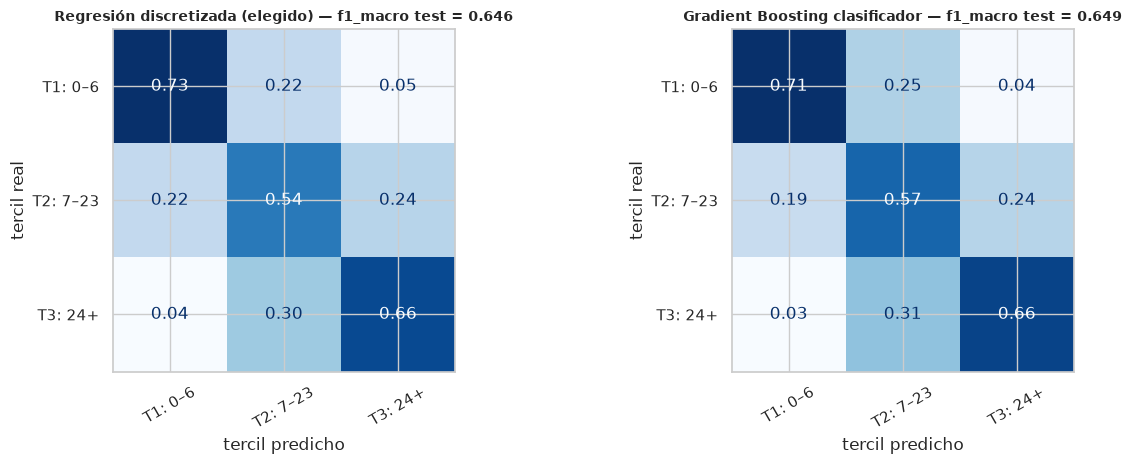

,lectura del error en el test
Acierto exacto,64.7%
Error de 1 tercil (vecino),32.3%
Error de 2 terciles (extremo a extremo),3.0%
"De los errores, % que cae en un tercil vecino",91.5%
Artículos top 10 % del test predichos en T3,83.0%
Artículos top 10 % del test predichos en T2 o T3,98.8%
Artículos predichos en T1 que en realidad son top 10 %,0.4%


In [30]:
# ============================================================
# 4.4 Evaluación única sobre X_test del clasificador por terciles
# ============================================================
modelo_q_final = clone(variantes_q["regresión discretizada · cortes por cuantil de la predicción"][0]).fit(X_train, y_reg_train)
modelo_q_gb = clone(busquedas_q["gradient boosting"].best_estimator_).fit(X_train, y_q_train)

pred_q_test = modelo_q_final.predict(X_test)
pred_q_gb_test = modelo_q_gb.predict(X_test)
pred_q_piso = np.full(len(y_q_test), y_q_train.mode()[0])

cortes_aprendidos = modelo_q_final[-1].cortes_
display(pd.DataFrame({
    "corte en log(1 + citas)": cortes_aprendidos,
    "equivale a citas predichas ≤": np.expm1(cortes_aprendidos).round(1),
    "corte real de citas (train)": CORTES_Q,
}, index=["T1|T2", "T2|T3"]).round(3))

resumen_test_q = pd.DataFrame({
    "Piso (clase más frecuente)": metricas_ordinales(y_q_test, pred_q_piso),
    "Gradient Boosting clasificador": metricas_ordinales(y_q_test, pred_q_gb_test),
    "Regresión discretizada (elegido)": metricas_ordinales(y_q_test, pred_q_test),
}).T
resumen_test_q.insert(1, "f1_macro cv", [
    tabla_q_cv.loc["piso (clase más frecuente)", "f1_macro cv"],
    tabla_q2.loc["gradient boosting clasificador (ajustado)", "f1_macro cv"],
    tabla_q2.loc["regresión discretizada · cortes por cuantil de la predicción", "f1_macro cv"],
])
display(resumen_test_q.round(3))

print(classification_report(y_q_test, pred_q_test, target_names=ETIQ_Q, digits=3))

# Matrices de confusión normalizadas por fila (recall de cada tercil)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (titulo, pred) in zip(axes, [("Regresión discretizada (elegido)", pred_q_test), ("Gradient Boosting clasificador", pred_q_gb_test)]):
    ConfusionMatrixDisplay.from_predictions(
        y_q_test, pred, normalize="true", display_labels=ETIQ_Q, cmap="Blues", values_format=".2f", ax=ax, colorbar=False,
    )
    ax.set_title(f"{titulo} — f1_macro test = {f1_score(y_q_test, pred, average='macro'):.3f}", fontsize=10, weight="bold")
    ax.set_xlabel("tercil predicho")
    ax.set_ylabel("tercil real")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

# Qué tan lejos se equivoca y cómo conversa con el Objetivo 2
distancia = np.abs(y_q_test.values - pred_q_test)
top10_test = y_clf_test.loc[X_test.index].values.astype(bool)
display(pd.Series({
    "Acierto exacto": f"{(distancia == 0).mean():.1%}",
    "Error de 1 tercil (vecino)": f"{(distancia == 1).mean():.1%}",
    "Error de 2 terciles (extremo a extremo)": f"{(distancia == 2).mean():.1%}",
    "De los errores, % que cae en un tercil vecino": f"{(distancia[distancia > 0] == 1).mean():.1%}",
    "Artículos top 10 % del test predichos en T3": f"{(pred_q_test[top10_test] == 2).mean():.1%}",
    "Artículos top 10 % del test predichos en T2 o T3": f"{(pred_q_test[top10_test] >= 1).mean():.1%}",
    "Artículos predichos en T1 que en realidad son top 10 %": f"{top10_test[pred_q_test == 0].mean():.1%}",
}).to_frame("lectura del error en el test"))

**Lectura del clasificador por terciles en el test (tocado una sola vez):**

- **Los cortes que aprendió el modelo:** en escala de citas predichas, los cortes quedan en **8,1 / 20,1** contra los cortes reales de **6 / 23**. El corte inferior sube y el superior baja porque el regresor comprime las predicciones hacia el centro: una predicción de 20 citas ya está en el tercio más alto de lo que el modelo predice. Ese es justamente el ajuste que en 4.3 evitó que T1 y T3 quedaran subrepresentados.
- **Test contra validación cruzada:** f1_macro **0,646** en el test contra **0,635 ± 0,011** en CV (+0,011), con accuracy de **64,7 %**, acierto ±1 tercil de **97,0 %**, MAE de **0,383** terciles y kappa cuadrático de **0,669**. Le gana con holgura al piso (f1_macro **0,172**, kappa **0,000**) y casi duplica al piso al azar de CV (**0,325**).
- **Contra el Gradient Boosting clasificador en el test:** quedan prácticamente empatados (f1_macro **0,649** vs **0,646**, kappa **0,672** vs **0,669**, acierto ±1 tercil **97,4 %** vs **97,0 %**), con diferencias menores que un desvío de CV. No cambiamos la elección mirando el test: la decisión se tomó en CV y elegir con el test sería usarlo como validación.
- **Dónde acierta y dónde no:** los extremos son los más fáciles (**T1: F1 0,743**, recall 0,733; **T3: F1 0,683**, recall 0,662). El tercil del medio (**T2: F1 0,512**) es el más difícil porque limita con los otros dos y lo separan pocas citas de cada lado (6 contra 7 o 23 contra 24), algo que las columnas disponibles al publicar no alcanzan a distinguir; es el mismo patrón del error por tramo de la Sección 2.5.
- **Qué tan lejos se equivoca:** **64,7 %** de acierto exacto, **32,3 %** con error de un tercil y sólo **3,0 %** de error extremo (T1↔T3). El **91,5 %** de los errores cae en un tercil vecino.
- **Puente con el Objetivo 2:** de los artículos top 10 % del test, el **83,0 %** queda predicho en T3 y el **98,8 %** en T2 o T3, mientras que de los predichos en T1 sólo el **0,4 %** es top 10 %. El clasificador por terciles sirve como un triage simple y robusto: separa con seguridad lo que casi seguro no va a destacar y concentra en el tercil alto a más de 8 de cada 10 artículos destacados.

**Conclusión del Objetivo 3:** al pasar de quintiles a terciles el problema se vuelve más fácil (f1_macro de test **0,646** con 3 clases, contra un piso al azar de 0,33) y casi desaparecen los errores extremos, pero también se achica la ventaja del regresor discretizado sobre un clasificador multiclase directo: en el test quedan empatados. Mantenemos la regresión del Objetivo 1 cortada por cuantiles porque gana en kappa en CV y permite que la aplicación de la Entrega 4 salga de un único modelo con tres lecturas: citas esperadas (Objetivo 1), probabilidad de top 10 % (Objetivo 2) y tercil de impacto (Objetivo 3).

---

## 5. Síntesis y respuestas directas a las preguntas de la Entrega 3

Cerramos el notebook dejando respondidas, con los números exactos obtenidos arriba, las **seis preguntas de defensa** planteadas en el instructivo:

| Pregunta del instructivo | Respuesta fundamentada en este notebook |
|---|---|
| **1. ¿Por qué esa métrica? ¿Qué error es más caro en tu problema y si la métrica lo ve?** | En **Regresión** usamos **MAE** sobre `log(1 + cited_by_count)` (acompañado de $R^2$) porque se lee en las unidades del objetivo y pesa igual a todos los artículos, evitando que el `1 %` de artículos con más de `279` citas domine la pérdida como haría el RMSE. En **Clasificación** (`is_top10_percent`, con `12,0 %` de positivos) la *accuracy* esconde a la clase chica (contestar siempre `False` da `88,0 %` de *accuracy*); por eso declaramos **`f1_macro`**, que promedia ambas clases `50/50` y penaliza por igual perder artículos destacados (*recall*) o llenar la predicción de falsas alarmas (*precision*). |
| **2. ¿Cuánto le gana tu modelo al piso, y si eso es mucho o poco para lo que querés hacer con él?** | En **Regresión**, el modelo elegido (`HistGradientBoostingRegressor`) baja el MAE en el test de **`1,159` (piso) a `0,704`** (una reducción de `0,455` puntos, más de 30 veces el desvío entre folds; notamos además que el `0,704` del test queda `0,019` por encima del `0,685 ± 0,011` de CV, un corrimiento que afecta por igual a `Ridge` —`0,709` a `0,730`— por casos más difíciles en `X_test`) y explica el **`60,8 %` de la varianza ($R^2 = 0,608$)**. En **Clasificación**, el modelo elegido (`Regresión Logística C=10` con umbral `0,31` adentro de `TunedThresholdClassifierCV`) pasa de **`0,468` (piso) a `0,709` de `f1_macro`** en el test (`0,718 ± 0,006` en CV anidada) y de `0,000` a **`0,488`** en el F1 de la clase `top 10 %`. Para la **Entrega 4**, ambos objetos (`Pipeline` y `TunedThresholdClassifierCV`) quedan listos para predecir con `predict()` sobre los metadatos iniciales del artículo. |
| **3. ¿Por qué los pedazos de la validación se arman así, y qué le pasaría al número si los armaras al azar (o por grupo)?** | Como todos los artículos son de `2019` y el mes no influye (H4: $\rho = -0,035$), no aplica corte temporal. Nuestro uso previsto es predecir artículos dentro del catálogo conocido de revistas de Ciencia de Materiales (el **`87,0 %`** de `X_test` pertenece a revistas presentes en `X_train`), por lo que la validación que imita el uso es `KFold` / `StratifiedKFold` por artículo. Al probar qué pasa si se evalúa sobre revistas nunca vistas (`GroupKFold` / `StratifiedGroupKFold` sobre las `2.213` revistas), `Ridge` casi no cambia (`0,709` a **`0,712`**), pero `Gradient Boosting` sube de **`0,689` a `0,702`** (`+0,013`, más de un desvío), achicando la ventaja pareada sobre `Ridge` de **`0,0204 ± 0,0051` (`5/5` folds)** en `KFold` a **`0,0098 ± 0,0105`** en `GroupKFold`. Es decir: para revistas conocidas gana `Boosting`; si se usara sobre revistas nuevas, por la regla del desvío convendría `Ridge`. |
| **4. ¿Por qué ese modelo y no uno más complejo (o más simple), con la diferencia y el desvío a la vista?** | Aplicamos la regla del instructivo (*«si el complejo no le gana al simple por más que el desvío, se queda el simple»*) en ambos objetivos: en **Regresión**, `Gradient Boosting` (`0,685 ± 0,011`) le gana a `Ridge` (`0,709 ± 0,014`) por **`0,024` de MAE** (`+0,020 ± 0,005` pareado, `5/5` folds) y empata con `Random Forest` (`0,687 ± 0,010`), por lo que se justifica el modelo complejo; además descartamos las 5 columnas en observación porque juntas bajan apenas `0,010` de MAE en `Boosting` (`1,0 %` en factor multiplicativo) a costa de casi triplicar las columnas (`21` a `57`). En cambio, en **Clasificación**, una vez ajustado el umbral en CV (`TunedThresholdClassifierCV`, umbral `0,31`), la **`Regresión Logística` (`0,718 ± 0,006`) empata con `Gradient Boosting` (`0,721 ± 0,012`)**, con una diferencia pareada de **`+0,003 ± 0,017`** (cinco veces menor que el desvío; y en `StratifiedGroupKFold` gana la logística `0,714` vs `0,713`), por lo que **se queda el modelo simple (`Regresión Logística`)**; en el test `Boosting` queda `0,018` arriba (`0,727` vs `0,709`), dentro de la variabilidad entre folds. |
| **5. Una confusión concreta del modelo, o un tramo donde erra mucho, y una explicación desde tu dominio.** | En **Regresión**, el modelo es muy preciso entre `5` y `49` citas (`MAE` de `0,53` a `0,66`), pero subestima el tramo de **`100+` citas** (mediana real `169` vs predicha `53,8`, `MAE = 1,296`): las variables previas miden el piso de visibilidad que dan la revista, la bibliografía y el grupo, pero un *hit* de `1.000` citas depende del hallazgo científico puntual. En **Clasificación**, los **`125` Falsos Positivos** son artículos en revistas de élite (*Applied Physics Reviews*, *ACS Catalysis*, *ACS Nano*, con `59–210` citas previas por trabajo) que recibieron `25–55` citas pero no llegaron al corte del `top 10 %` de su subtema; y los **`127` Falsos Negativos** combinan éxitos inesperados en revistas chicas (hasta `360` citas en una revista con `21,8` citas previas por trabajo), artículos con bibliografías muy cortas o metadatos de referencias incompletos y el solapamiento del corte de `is_top10_percent` de OpenAlex entre subtemas finos (en el test hay `top 10 %` con `22` citas y no `top 10 %` con `93`). |
| **6. La columna que más pesa, y qué hiciste para descartar que sea una fuga.** | Las dos columnas que más pesan son **`referenced_works_count`** (`+0,250` en MAE y `+0,096` en `f1_macro` al permutar) y **`source_pre_cites_per_work`** (`+0,247` en MAE y `+0,127` en `f1_macro`). Descartamos fuga en **todas** las columnas con evidencia empírica (Secciones 2.3 y 2.5 bis): (1) **`referenced_works_count`** queda fija en el PDF al publicar (`100 %` son `type == "article"`), los ceros por metadatos faltantes se aíslan con `sin_referencias`, y **dentro de la misma revista** correlaciona positivamente con las citas en el **`95,2 %` de las revistas** (mediana $\rho = 0,250$); (2) **`source_pre_cites_per_work`** se calculó sólo con trabajos de **2012–2018** (previos a 2019); (3) en **`oa_status`**, pasar `green` y `bronze` a `closed` mueve el MAE apenas `+0,001`; y (4) en **`in_pubmed`** (que es `0 %` o `100 %` por revista en el `88,2 %` de las revistas) e **`institution_max_h_index`**, quitarlas por ablación en CV cambia el MAE en **`+0,0011 ± 0,0007`** y **`+0,0023 ± 0,0015`**, confirmando que el modelo no depende de información posterior a la publicación. |